# Automotive Price Intelligence & Prediction

## Project Overview

This project uses historical automobile import data to analyse vehicle characteristics and predict automobile prices using machine learning regression techniques.

The project covers exploratory data analysis, data cleaning, feature preprocessing, model development, hyperparameter optimisation, model evaluation and prediction.

## Project Objective

The objective is to identify the vehicle characteristics associated with price variation and develop a reliable regression model that can help management understand automobile pricing patterns in a new market.

## Dataset Overview

- Dataset: 1985 Auto Imports Database
- Records: 201
- Total attributes: 26
- Independent variables: 25
- Target variable: `price`

## 1. Environment Setup and Data Loading

The project uses Python and its data science libraries to perform data analysis and develop machine learning models.

The dataset is loaded into a Pandas DataFrame. The original dataset contains automobile specifications and their corresponding prices.

The column names are assigned based on the dataset documentation, and missing values represented by `?` are interpreted as null values.

In [1]:
import sys
import pandas as pd
import numpy as np
import sklearn

print("Python:", sys.version)
print("Environment:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Python: 3.13.17 (tags/v3.13.17:64e080d, Oct 21 2026, 14:08:53) [MSC v.1944 64 bit (AMD64)]
Environment: C:\Rakesh Project\Automotive-Price-Intelligence\.venv\Scripts\python.exe
Pandas: 3.1.1
NumPy: 2.5.4
Scikit-learn: 1.9.1


In [2]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

warnings.filterwarnings("ignore")

# Project paths
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "auto_imports.csv"
PROCESSED_PATH = PROJECT_ROOT / "data" / "processed"
MODEL_PATH = PROJECT_ROOT / "models"
VISUALIZATION_PATH = PROJECT_ROOT / "visualizations"
REPORT_PATH = PROJECT_ROOT / "reports"

# Visualisation settings
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", DATA_PATH.exists())
print("Notebook setup completed.")

Project root: C:\Rakesh Project\Automotive-Price-Intelligence
Dataset exists: True
Notebook setup completed.


In [3]:
columns = [
    "symboling", "normalized_losses", "make", "fuel_type",
    "aspiration", "num_of_doors", "body_style", "drive_wheels",
    "engine_location", "wheel_base", "length", "width", "height",
    "curb_weight", "engine_type", "num_of_cylinders", "engine_size",
    "fuel_system", "bore", "stroke", "compression_ratio",
    "horsepower", "peak_rpm", "city_mpg", "highway_mpg", "price"
]

df = pd.read_csv(
    DATA_PATH,
    header=None,
    names=columns,
    na_values="?",
    skipinitialspace=True
)

print("Dataset loaded successfully.")
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nFirst 5 records:")
display(df.head())

Dataset loaded successfully.
Shape: (201, 26)

Column names:
['symboling', 'normalized_losses', 'make', 'fuel_type', 'aspiration', 'num_of_doors', 'body_style', 'drive_wheels', 'engine_location', 'wheel_base', 'length', 'width', 'height', 'curb_weight', 'engine_type', 'num_of_cylinders', 'engine_size', 'fuel_system', 'bore', 'stroke', 'compression_ratio', 'horsepower', 'peak_rpm', 'city_mpg', 'highway_mpg', 'price']

First 5 records:


,symboling,normalized_losses,make,fuel_type,aspiration,num_of_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450


## 2. Initial Data Inspection

The initial inspection examines the dataset structure, dimensions, column names, data types and basic statistical information.

This step helps identify the types of variables, understand the available data and detect potential data quality issues before performing detailed analysis.

In [4]:
print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

df.info()

print("\n" + "=" * 60)
print("MISSING VALUES BY COLUMN")
print("=" * 60)

missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing[missing["Missing_Count"] > 0].sort_values(
    "Missing_Count", ascending=False
))

print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Missing target prices:", df["price"].isnull().sum())
print("Unique manufacturers:", df["make"].nunique())
print("Unique car models by manufacturer:", df["make"].value_counts().to_dict())

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized_losses  164 non-null    float64
 2   make               201 non-null    str    
 3   fuel_type          201 non-null    str    
 4   aspiration         201 non-null    str    
 5   num_of_doors       199 non-null    str    
 6   body_style         201 non-null    str    
 7   drive_wheels       201 non-null    str    
 8   engine_location    201 non-null    str    
 9   wheel_base         201 non-null    float64
 10  length             201 non-null    float64
 11  width              201 non-null    float64
 12  height             201 non-null    float64
 13  curb_weight        201 non-null    int64  
 14  engine_type        201 non-null    str    
 15  num_of_cylinders   201 non-null    str    
 16  engine_size      

,Missing_Count,Missing_Percentage
normalized_losses,37,18.41
bore,4,1.99
stroke,4,1.99
num_of_doors,2,1.00
horsepower,2,1.00
peak_rpm,2,1.00



Total missing values: 51
Duplicate rows: 0
Missing target prices: 0
Unique manufacturers: 22
Unique car models by manufacturer: {'toyota': 32, 'nissan': 18, 'mazda': 17, 'honda': 13, 'mitsubishi': 13, 'subaru': 12, 'volkswagen': 12, 'peugot': 11, 'volvo': 11, 'dodge': 9, 'bmw': 8, 'mercedes-benz': 8, 'plymouth': 7, 'audi': 6, 'saab': 6, 'porsche': 4, 'alfa-romero': 3, 'chevrolet': 3, 'jaguar': 3, 'isuzu': 2, 'renault': 2, 'mercury': 1}


## 3. Dataset Composition and Feature Types

The dataset contains both numerical and categorical variables.

Numerical variables represent measurable vehicle characteristics, while categorical variables describe vehicle categories and specifications.

Separating these feature types helps select suitable analysis methods and preprocessing techniques for each group.

In [5]:
# Separate numerical and categorical columns
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:", len(numerical_columns))
print("Categorical columns:", len(categorical_columns))

print("\nNUMERICAL SUMMARY")
display(df[numerical_columns].describe().T.round(2))

print("\nCATEGORICAL SUMMARY")
display(df[categorical_columns].describe().T)

print("\nTARGET VARIABLE – PRICE")
print("Minimum:", df["price"].min())
print("Maximum:", df["price"].max())
print("Mean:", round(df["price"].mean(), 2))
print("Median:", df["price"].median())
print("Standard Deviation:", round(df["price"].std(), 2))

Numerical columns: 16
Categorical columns: 10

NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
symboling,201.0,0.84,1.25,-2.00,0.00,1.00,2.00,3.00
normalized_losses,164.0,122.00,35.44,65.00,94.00,115.00,150.00,256.00
wheel_base,201.0,98.80,6.07,86.60,94.50,97.00,102.40,120.90
length,201.0,174.20,12.32,141.10,166.80,173.20,183.50,208.10
width,201.0,65.89,2.10,60.30,64.10,65.50,66.60,72.00
height,201.0,53.77,2.45,47.80,52.00,54.10,55.50,59.80
curb_weight,201.0,2555.67,517.30,1488.00,2169.00,2414.00,2926.00,4066.00
engine_size,201.0,126.88,41.55,61.00,98.00,120.00,141.00,326.00
bore,197.0,3.33,0.27,2.54,3.15,3.31,3.59,3.94
stroke,197.0,3.26,0.32,2.07,3.11,3.29,3.41,4.17



CATEGORICAL SUMMARY


,count,unique,top,freq
make,201,22,toyota,32
fuel_type,201,2,gas,181
aspiration,201,2,std,165
num_of_doors,199,2,four,113
body_style,201,5,sedan,94
drive_wheels,201,3,fwd,118
engine_location,201,2,front,198
engine_type,201,6,ohc,145
num_of_cylinders,201,7,four,157
fuel_system,201,8,mpfi,92



TARGET VARIABLE – PRICE
Minimum: 5118
Maximum: 45400
Mean: 13207.13
Median: 10295.0
Standard Deviation: 7947.07


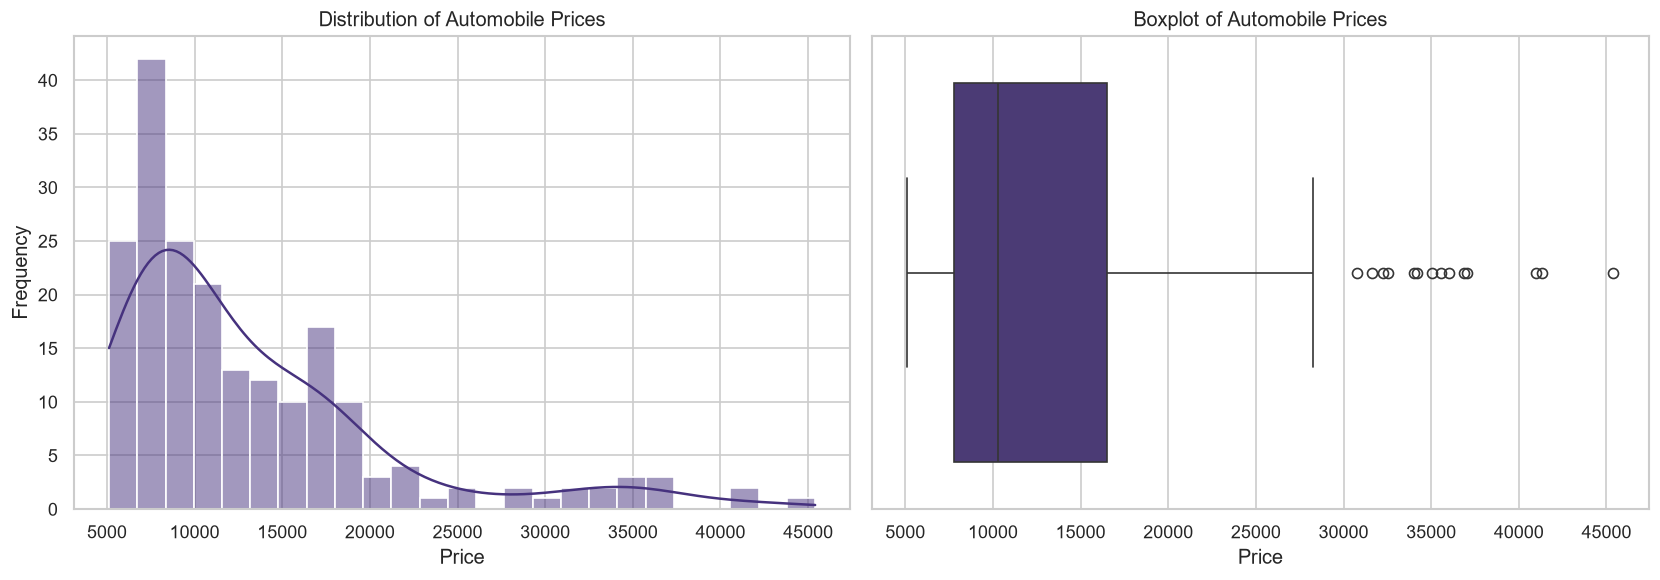

Price skewness: 1.81
Price kurtosis: 3.232


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["price"], kde=True, bins=25, ax=axes[0])
axes[0].set_title("Distribution of Automobile Prices")
axes[0].set_xlabel("Price")
axes[0].set_ylabel("Frequency")

sns.boxplot(x=df["price"], ax=axes[1])
axes[1].set_title("Boxplot of Automobile Prices")
axes[1].set_xlabel("Price")

plt.tight_layout()
plt.show()

print("Price skewness:", round(df["price"].skew(), 3))
print("Price kurtosis:", round(df["price"].kurtosis(), 3))

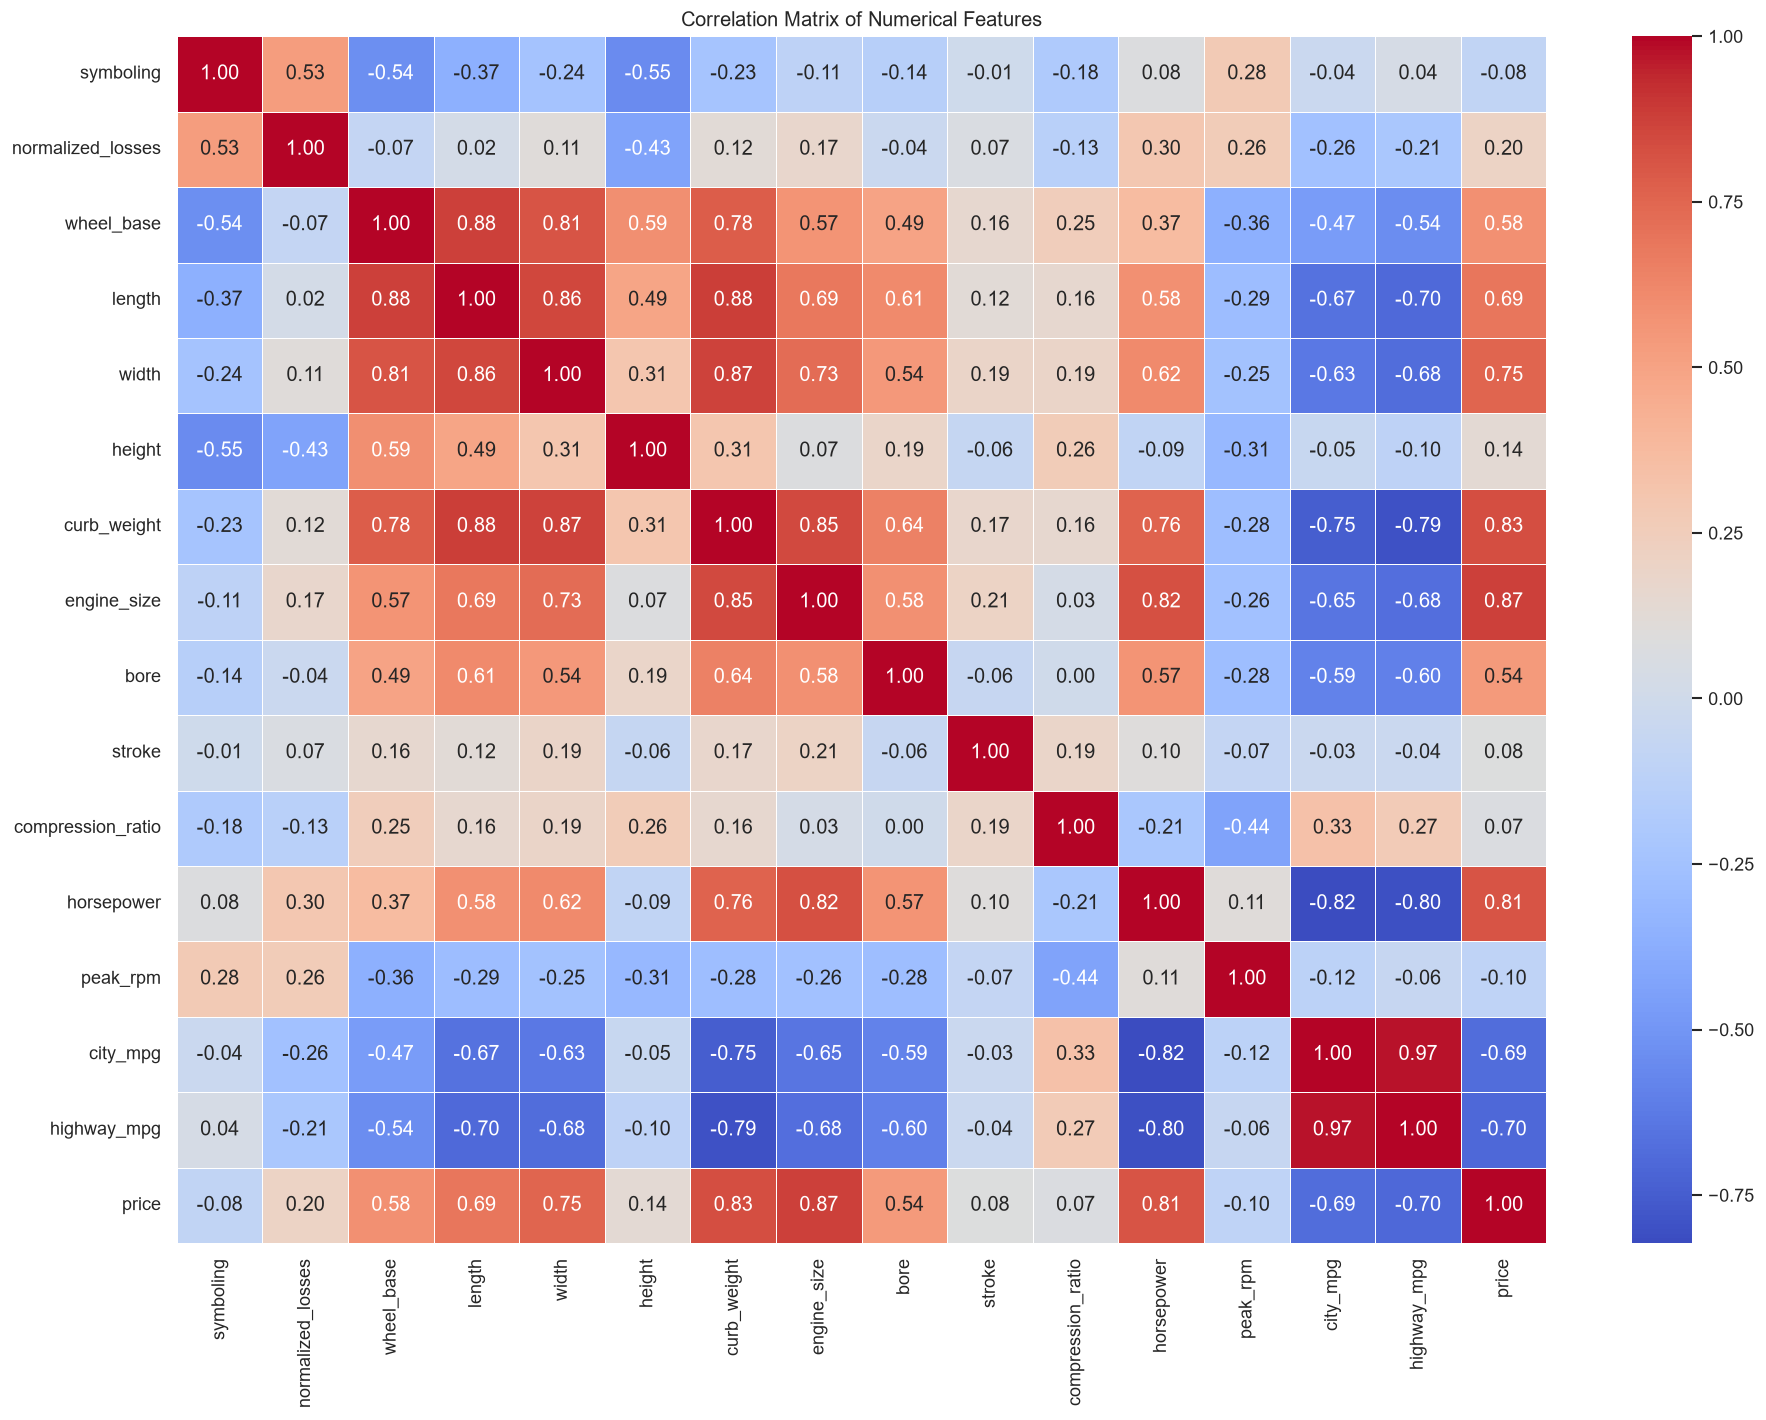


Top correlations with automobile price:


,Correlation_with_Price
engine_size,0.872335
curb_weight,0.834415
horsepower,0.810533
width,0.751265
highway_mpg,-0.704692
length,0.690628
city_mpg,-0.686571
wheel_base,0.584642
bore,0.543436
normalized_losses,0.203254


In [7]:
plt.figure(figsize=(16, 12))

correlation_matrix = df[numerical_columns].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.savefig(
    VISUALIZATION_PATH / "01_correlation_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nTop correlations with automobile price:")
display(
    correlation_matrix["price"]
    .drop("price")
    .sort_values(key=abs, ascending=False)
    .to_frame("Correlation_with_Price")
)

## 4. Categorical Data Analysis

Categorical variables are analysed to understand the distribution of manufacturers, fuel types, body styles, drive systems and other vehicle characteristics.

Price differences across categorical groups are also examined to identify patterns in the historical automobile dataset.

Group-level price comparisons should be interpreted carefully, particularly where the number of observations is small.


MAKE – VALUE COUNTS


,Count
make,
toyota,32
nissan,18
mazda,17
honda,13
mitsubishi,13
subaru,12
volkswagen,12
peugot,11
volvo,11



FUEL_TYPE – VALUE COUNTS


,Count
fuel_type,
gas,181
diesel,20



ASPIRATION – VALUE COUNTS


,Count
aspiration,
std,165
turbo,36


... (10 outputs left out)


NUM_OF_CYLINDERS – VALUE COUNTS


,Count
num_of_cylinders,
four,157
six,24
five,10
two,4
eight,4
three,1
twelve,1



FUEL_SYSTEM – VALUE COUNTS


,Count
fuel_system,
mpfi,92
2bbl,64
idi,20
1bbl,11
spdi,9
4bbl,3
mfi,1
spfi,1


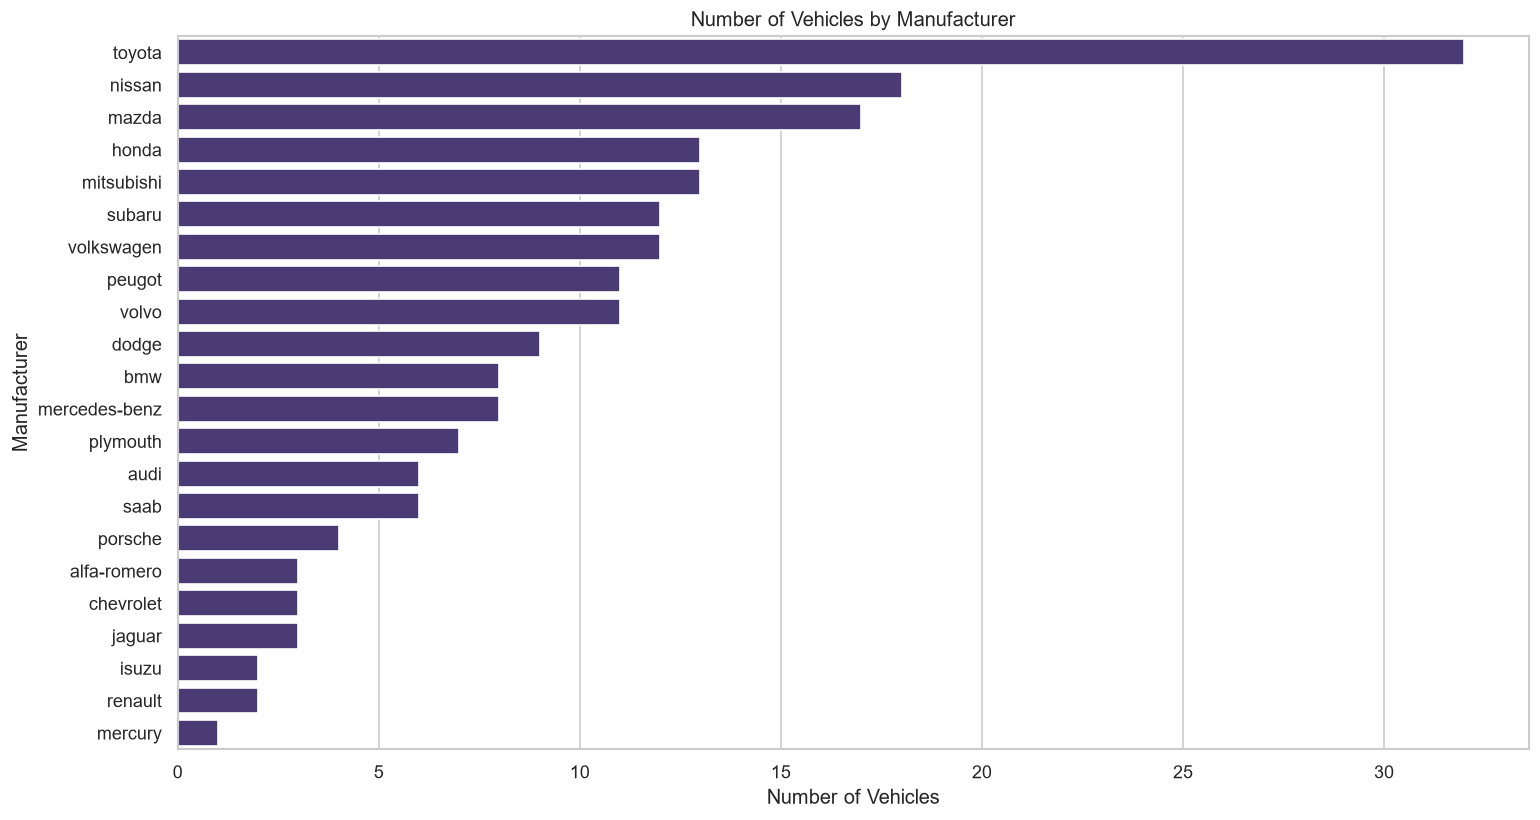

In [8]:
# Analyse manufacturer and categorical feature distributions

for column in categorical_columns:
    print(f"\n{'=' * 55}")
    print(f"{column.upper()} – VALUE COUNTS")
    print("=" * 55)
    display(
        df[column]
        .value_counts(dropna=False)
        .to_frame("Count")
    )

# Save manufacturer distribution
plt.figure(figsize=(13, 7))

sns.countplot(
    data=df,
    y="make",
    order=df["make"].value_counts().index
)

plt.title("Number of Vehicles by Manufacturer")
plt.xlabel("Number of Vehicles")
plt.ylabel("Manufacturer")
plt.tight_layout()

plt.savefig(
    VISUALIZATION_PATH / "02_manufacturer_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

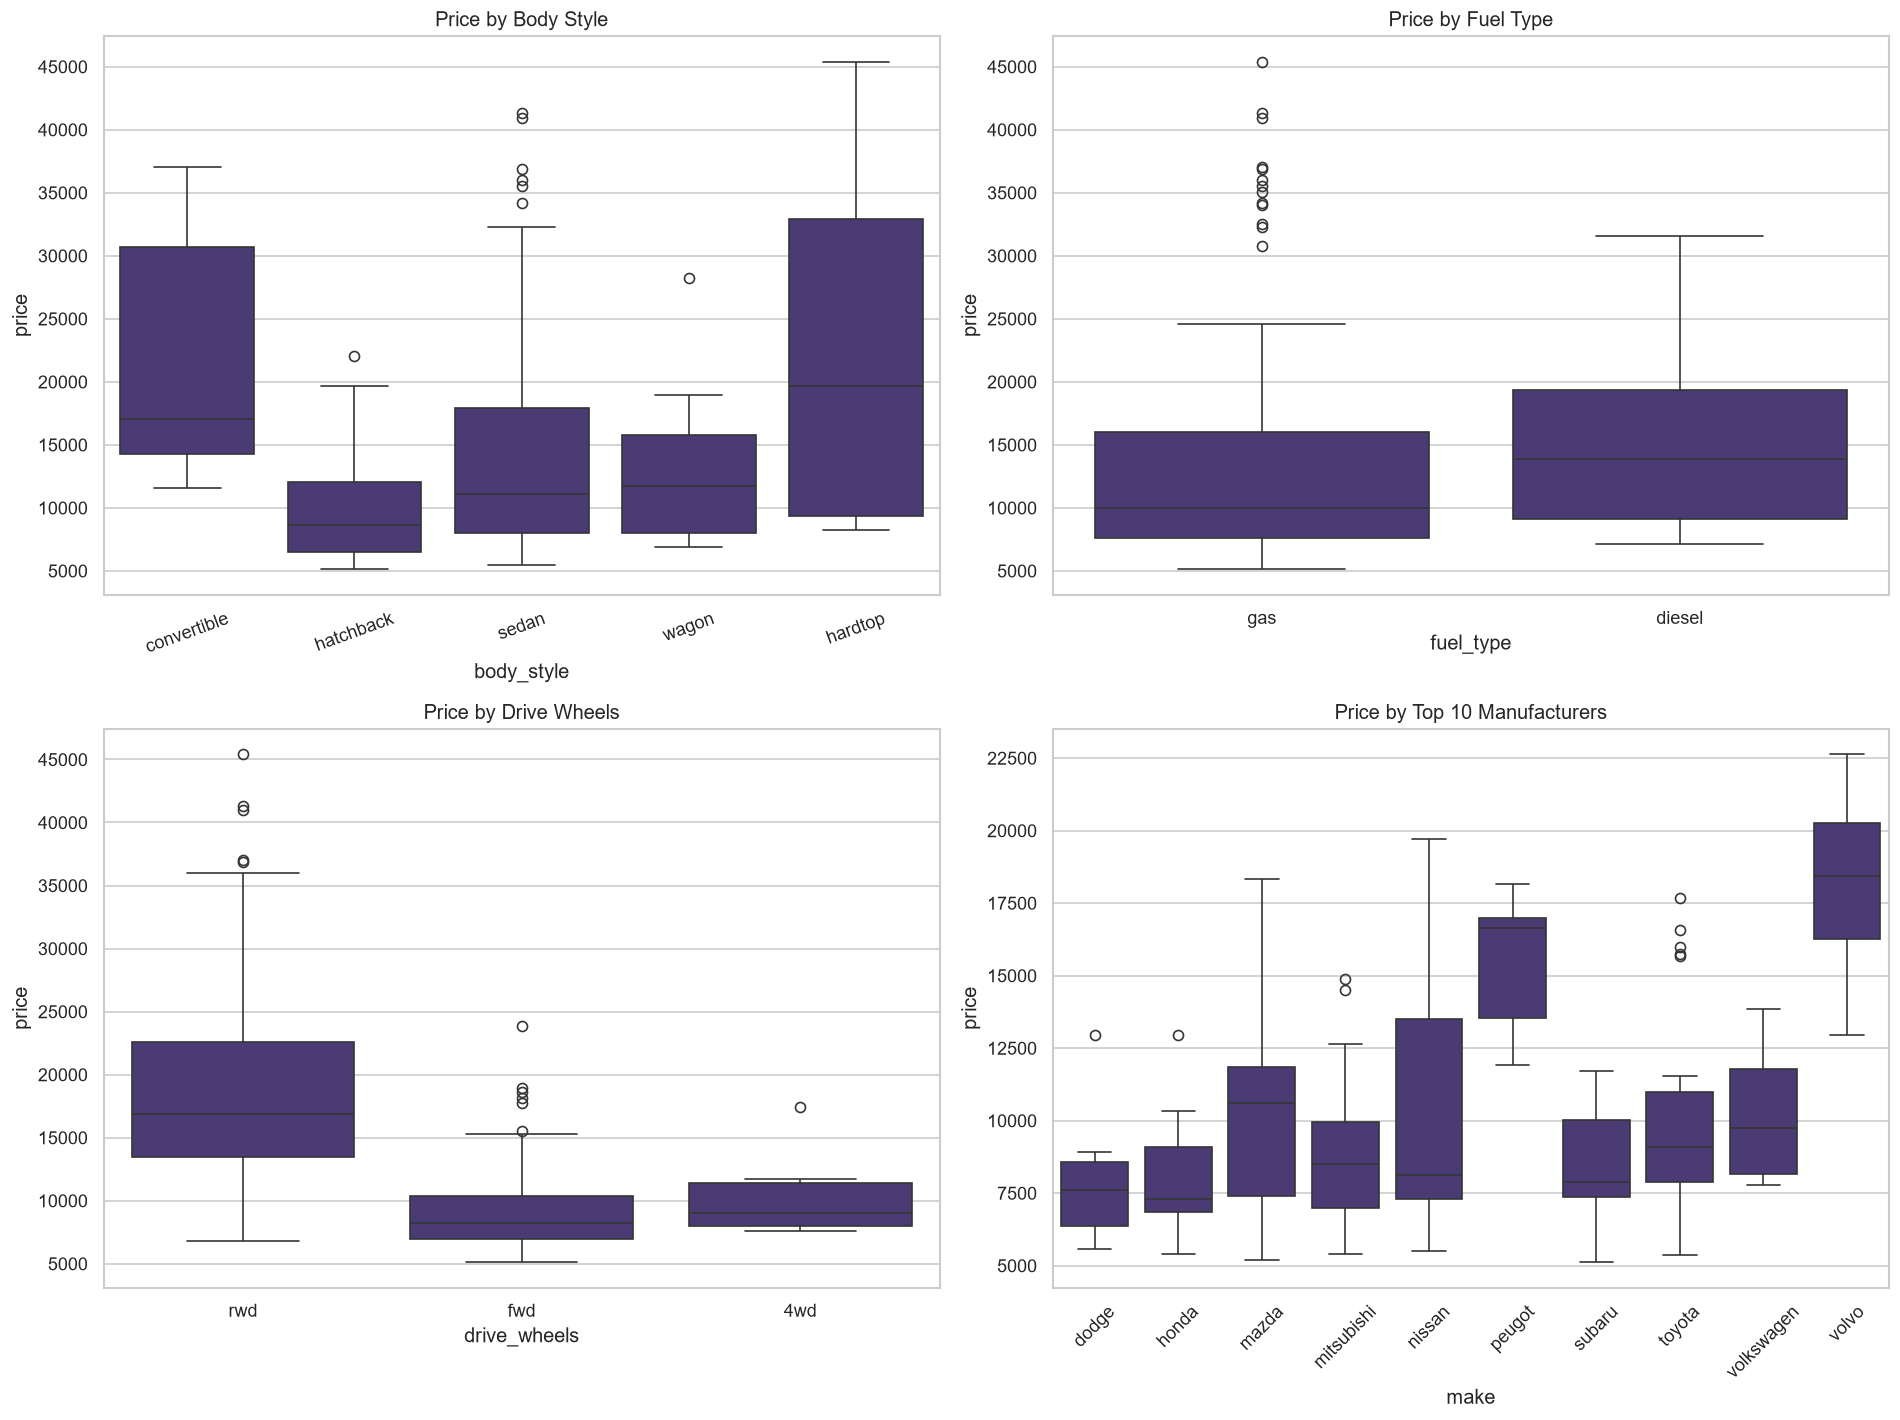

Median price by body style:


,count,median,mean
body_style,,,
convertible,6,17084.5,21890.50
hardtop,8,19687.5,22208.50
hatchback,68,8672.0,9957.44
sedan,94,11078.5,14459.76
wagon,25,11694.0,12371.96



Median price by manufacturer (top 10 by record count):


,count,median,mean
make,,,
volvo,11,18420.0,18063.18
peugot,11,16630.0,15489.09
mazda,17,10595.0,10652.88
volkswagen,12,9737.5,10077.50
toyota,32,9103.0,9885.81
mitsubishi,13,8499.0,9239.77
nissan,18,8124.0,10415.67
subaru,12,7894.0,8541.25
dodge,9,7609.0,7875.44


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

sns.boxplot(data=df, x="body_style", y="price", ax=axes[0, 0])
axes[0, 0].set_title("Price by Body Style")
axes[0, 0].tick_params(axis="x", rotation=20)

sns.boxplot(data=df, x="fuel_type", y="price", ax=axes[0, 1])
axes[0, 1].set_title("Price by Fuel Type")

sns.boxplot(data=df, x="drive_wheels", y="price", ax=axes[1, 0])
axes[1, 0].set_title("Price by Drive Wheels")

top_manufacturers = df["make"].value_counts().head(10).index

sns.boxplot(
    data=df[df["make"].isin(top_manufacturers)],
    x="make",
    y="price",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Price by Top 10 Manufacturers")
axes[1, 1].tick_params(axis="x", rotation=45)

plt.tight_layout()

plt.savefig(
    VISUALIZATION_PATH / "03_categorical_price_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Median price by body style:")
display(df.groupby("body_style")["price"].agg(["count", "median", "mean"]).round(2))

print("\nMedian price by manufacturer (top 10 by record count):")
display(
    df[df["make"].isin(top_manufacturers)]
    .groupby("make")["price"]
    .agg(["count", "median", "mean"])
    .sort_values("median", ascending=False)
    .round(2)
)

## 5. Numerical Data Analysis

Numerical variables are examined using descriptive statistics and distribution plots.

This analysis helps understand the range, central tendency, spread and distribution of vehicle characteristics such as engine size, horsepower, vehicle dimensions, weight and fuel efficiency.

Understanding these distributions helps identify unusual observations and potential preprocessing requirements.

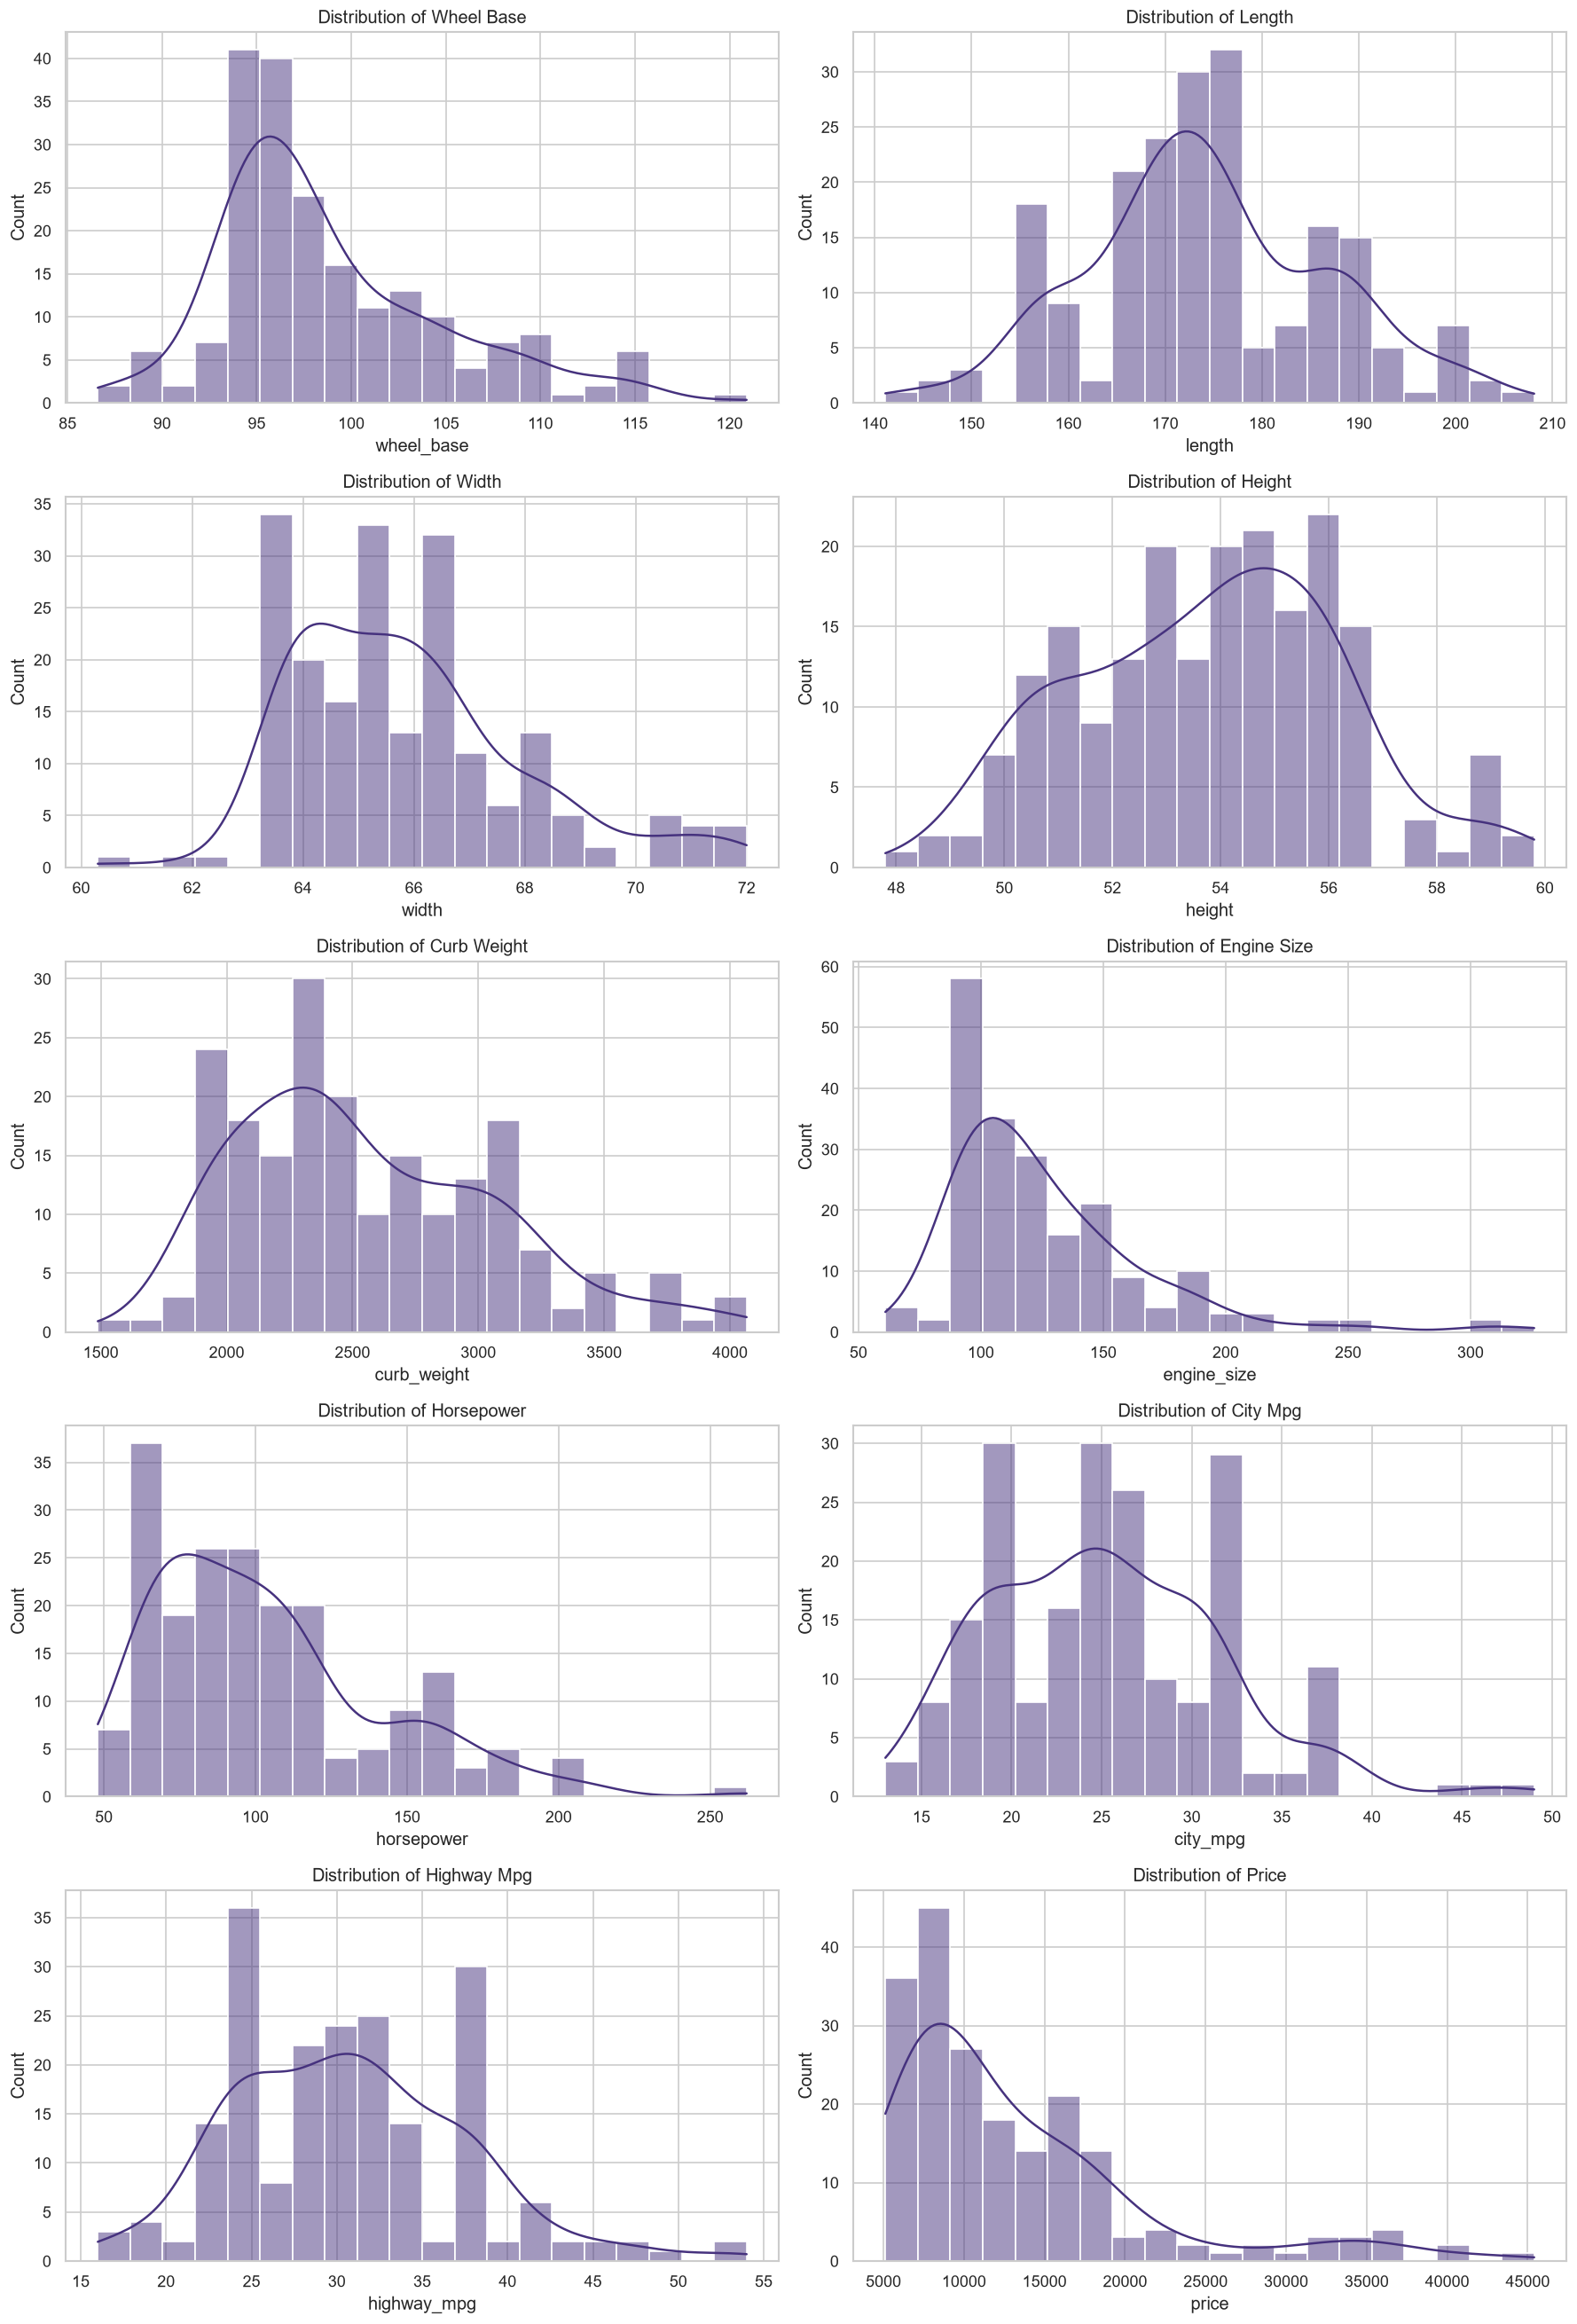

In [10]:
# Distribution plots for numerical variables

plot_columns = [
    "wheel_base", "length", "width", "height",
    "curb_weight", "engine_size", "horsepower",
    "city_mpg", "highway_mpg", "price"
]

fig, axes = plt.subplots(5, 2, figsize=(15, 22))

for column, ax in zip(plot_columns, axes.flatten()):
    sns.histplot(df[column], kde=True, ax=ax, bins=20)
    ax.set_title(f"Distribution of {column.replace('_', ' ').title()}")

plt.tight_layout()

plt.savefig(
    VISUALIZATION_PATH / "04_numerical_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Outlier Analysis

Potential outliers in automobile prices are examined using the Interquartile Range (IQR) method.

The analysis identifies observations with unusually high or low values relative to the overall price distribution.

High-priced vehicles are investigated to determine whether they represent possible data errors or genuine premium and high-performance automobiles.

Valid observations are retained rather than automatically removed, as they may contain important pricing information.

In [11]:
outlier_results = []

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = (
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ).sum()

    outlier_results.append({
        "Feature": column,
        "Lower_Limit": round(lower_limit, 2),
        "Upper_Limit": round(upper_limit, 2),
        "Outlier_Count": int(outlier_count)
    })

outlier_df = pd.DataFrame(outlier_results)

display(
    outlier_df.sort_values(
        "Outlier_Count", ascending=False
    ).reset_index(drop=True)
)

,Feature,Lower_Limit,Upper_Limit,Outlier_Count
0,compression_ratio,7.40,10.60,27
1,stroke,2.66,3.86,20
2,price,-5312.50,29587.50,14
3,width,60.35,70.35,11
4,engine_size,33.50,205.50,10
5,horsepower,1.00,185.00,5
6,wheel_base,82.65,114.25,3
7,highway_mpg,11.50,47.50,3
8,curb_weight,1033.50,4061.50,2
9,city_mpg,2.50,46.50,2


In [12]:
# Examine the 14 potential price outliers

Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

upper_price_limit = Q3 + 1.5 * IQR

high_price_cars = df[df["price"] > upper_price_limit].sort_values(
    "price", ascending=False
)

print("Upper price outlier threshold:", upper_price_limit)
print("Number of high-priced vehicles:", len(high_price_cars))

display(
    high_price_cars[
        ["make", "body_style", "fuel_type", "engine_size",
         "horsepower", "curb_weight", "price"]
    ]
)

Upper price outlier threshold: 29587.5
Number of high-priced vehicles: 14


,make,body_style,fuel_type,engine_size,horsepower,curb_weight,price
71,mercedes-benz,hardtop,gas,304,184.0,3715,45400
15,bmw,sedan,gas,209,182.0,3380,41315
70,mercedes-benz,sedan,gas,308,184.0,3900,40960
125,porsche,convertible,gas,194,207.0,2800,37028
16,bmw,sedan,gas,209,182.0,3505,36880
46,jaguar,sedan,gas,326,262.0,3950,36000
45,jaguar,sedan,gas,258,176.0,4066,35550
69,mercedes-benz,convertible,gas,234,155.0,3685,35056
68,mercedes-benz,sedan,gas,234,155.0,3740,34184
124,porsche,hardtop,gas,194,207.0,2756,34028


## 7. Missing Value Analysis

Missing values are examined across the dataset to identify incomplete vehicle records and determine which features require preprocessing.

The supplied dataset contains missing values in several independent variables, including normalized losses, number of doors, bore, stroke, horsepower and peak RPM.

The target variable, price, contains no missing values in the supplied CSV file.

Missing values are handled later through preprocessing pipelines using median imputation for numerical variables and most-frequent-value imputation for categorical variables.

In [13]:
# Missing-value analysis

missing_rows = df[df.isnull().any(axis=1)]

print("Records containing missing values:", len(missing_rows))
print("Total missing cells:", df.isnull().sum().sum())

print("\nMissing values by manufacturer:")
display(
    missing_rows.groupby("make")
    .agg(
        Records_With_Missing=("make", "size"),
        Missing_Values=("make", lambda x: df.loc[x.index].isnull().sum().sum())
    )
    .sort_values("Missing_Values", ascending=False)
)

print("\nMissing-value combinations:")
display(
    df[df.isnull().any(axis=1)]
    [["make", "normalized_losses", "num_of_doors",
      "bore", "stroke", "horsepower", "peak_rpm"]]
    .head(20)
)

Records containing missing values: 42
Total missing cells: 51

Missing values by manufacturer:


,Records_With_Missing,Missing_Values
make,,
mazda,6,11
renault,2,6
peugot,4,4
bmw,4,4
volkswagen,4,4
mitsubishi,3,3
mercedes-benz,3,3
alfa-romero,3,3
porsche,3,3



Missing-value combinations:


,make,normalized_losses,num_of_doors,bore,stroke,horsepower,peak_rpm
0,alfa-romero,NaN,two,3.47,2.68,111.0,5000.0
1,alfa-romero,NaN,two,3.47,2.68,111.0,5000.0
2,alfa-romero,NaN,two,2.68,3.47,154.0,5000.0
5,audi,NaN,two,3.19,3.40,110.0,5500.0
7,audi,NaN,four,3.19,3.40,110.0,5500.0
13,bmw,NaN,four,3.31,3.19,121.0,4250.0
14,bmw,NaN,four,3.62,3.39,182.0,5400.0
15,bmw,NaN,two,3.62,3.39,182.0,5400.0
16,bmw,NaN,four,3.62,3.39,182.0,5400.0
26,dodge,148.0,NaN,3.03,3.39,102.0,5500.0


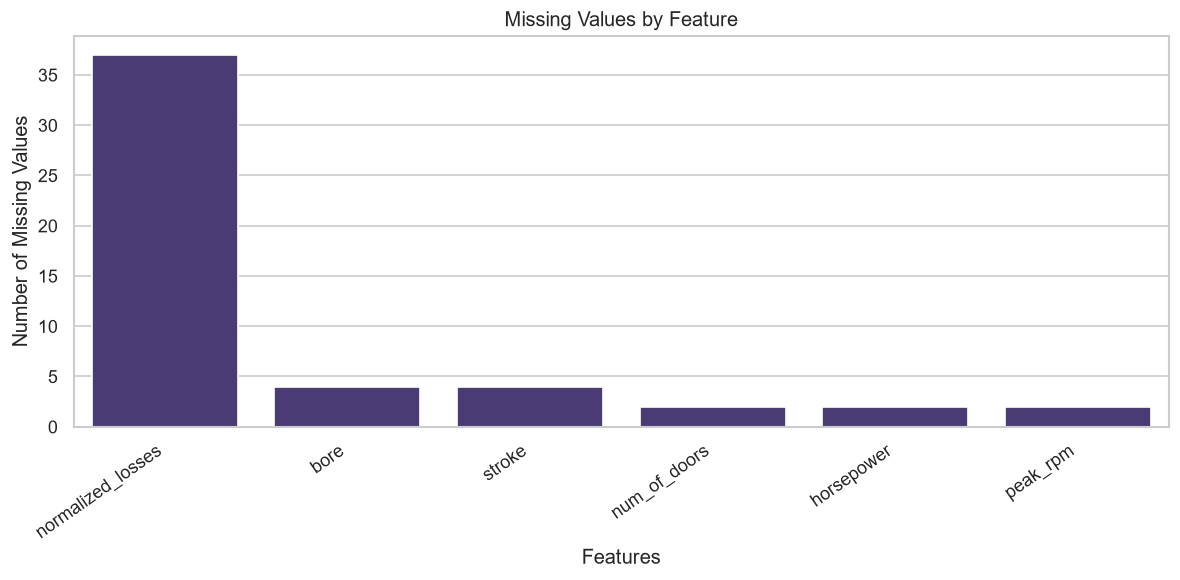

In [14]:
missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(
    ascending=False
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_counts.index,
    y=missing_counts.values
)

plt.title("Missing Values by Feature")
plt.xlabel("Features")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()

plt.savefig(
    VISUALIZATION_PATH / "05_missing_values_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8. Feature Relationships with Vehicle Price

The relationships between numerical vehicle characteristics and automobile prices are examined using scatter plots and correlation analysis.

Pearson correlation measures the strength and direction of linear relationships, while Spearman correlation helps identify monotonic relationships that may not be strictly linear.

These analyses help identify features that may contain useful information for predicting automobile prices.

Correlation indicates association and does not establish causation.

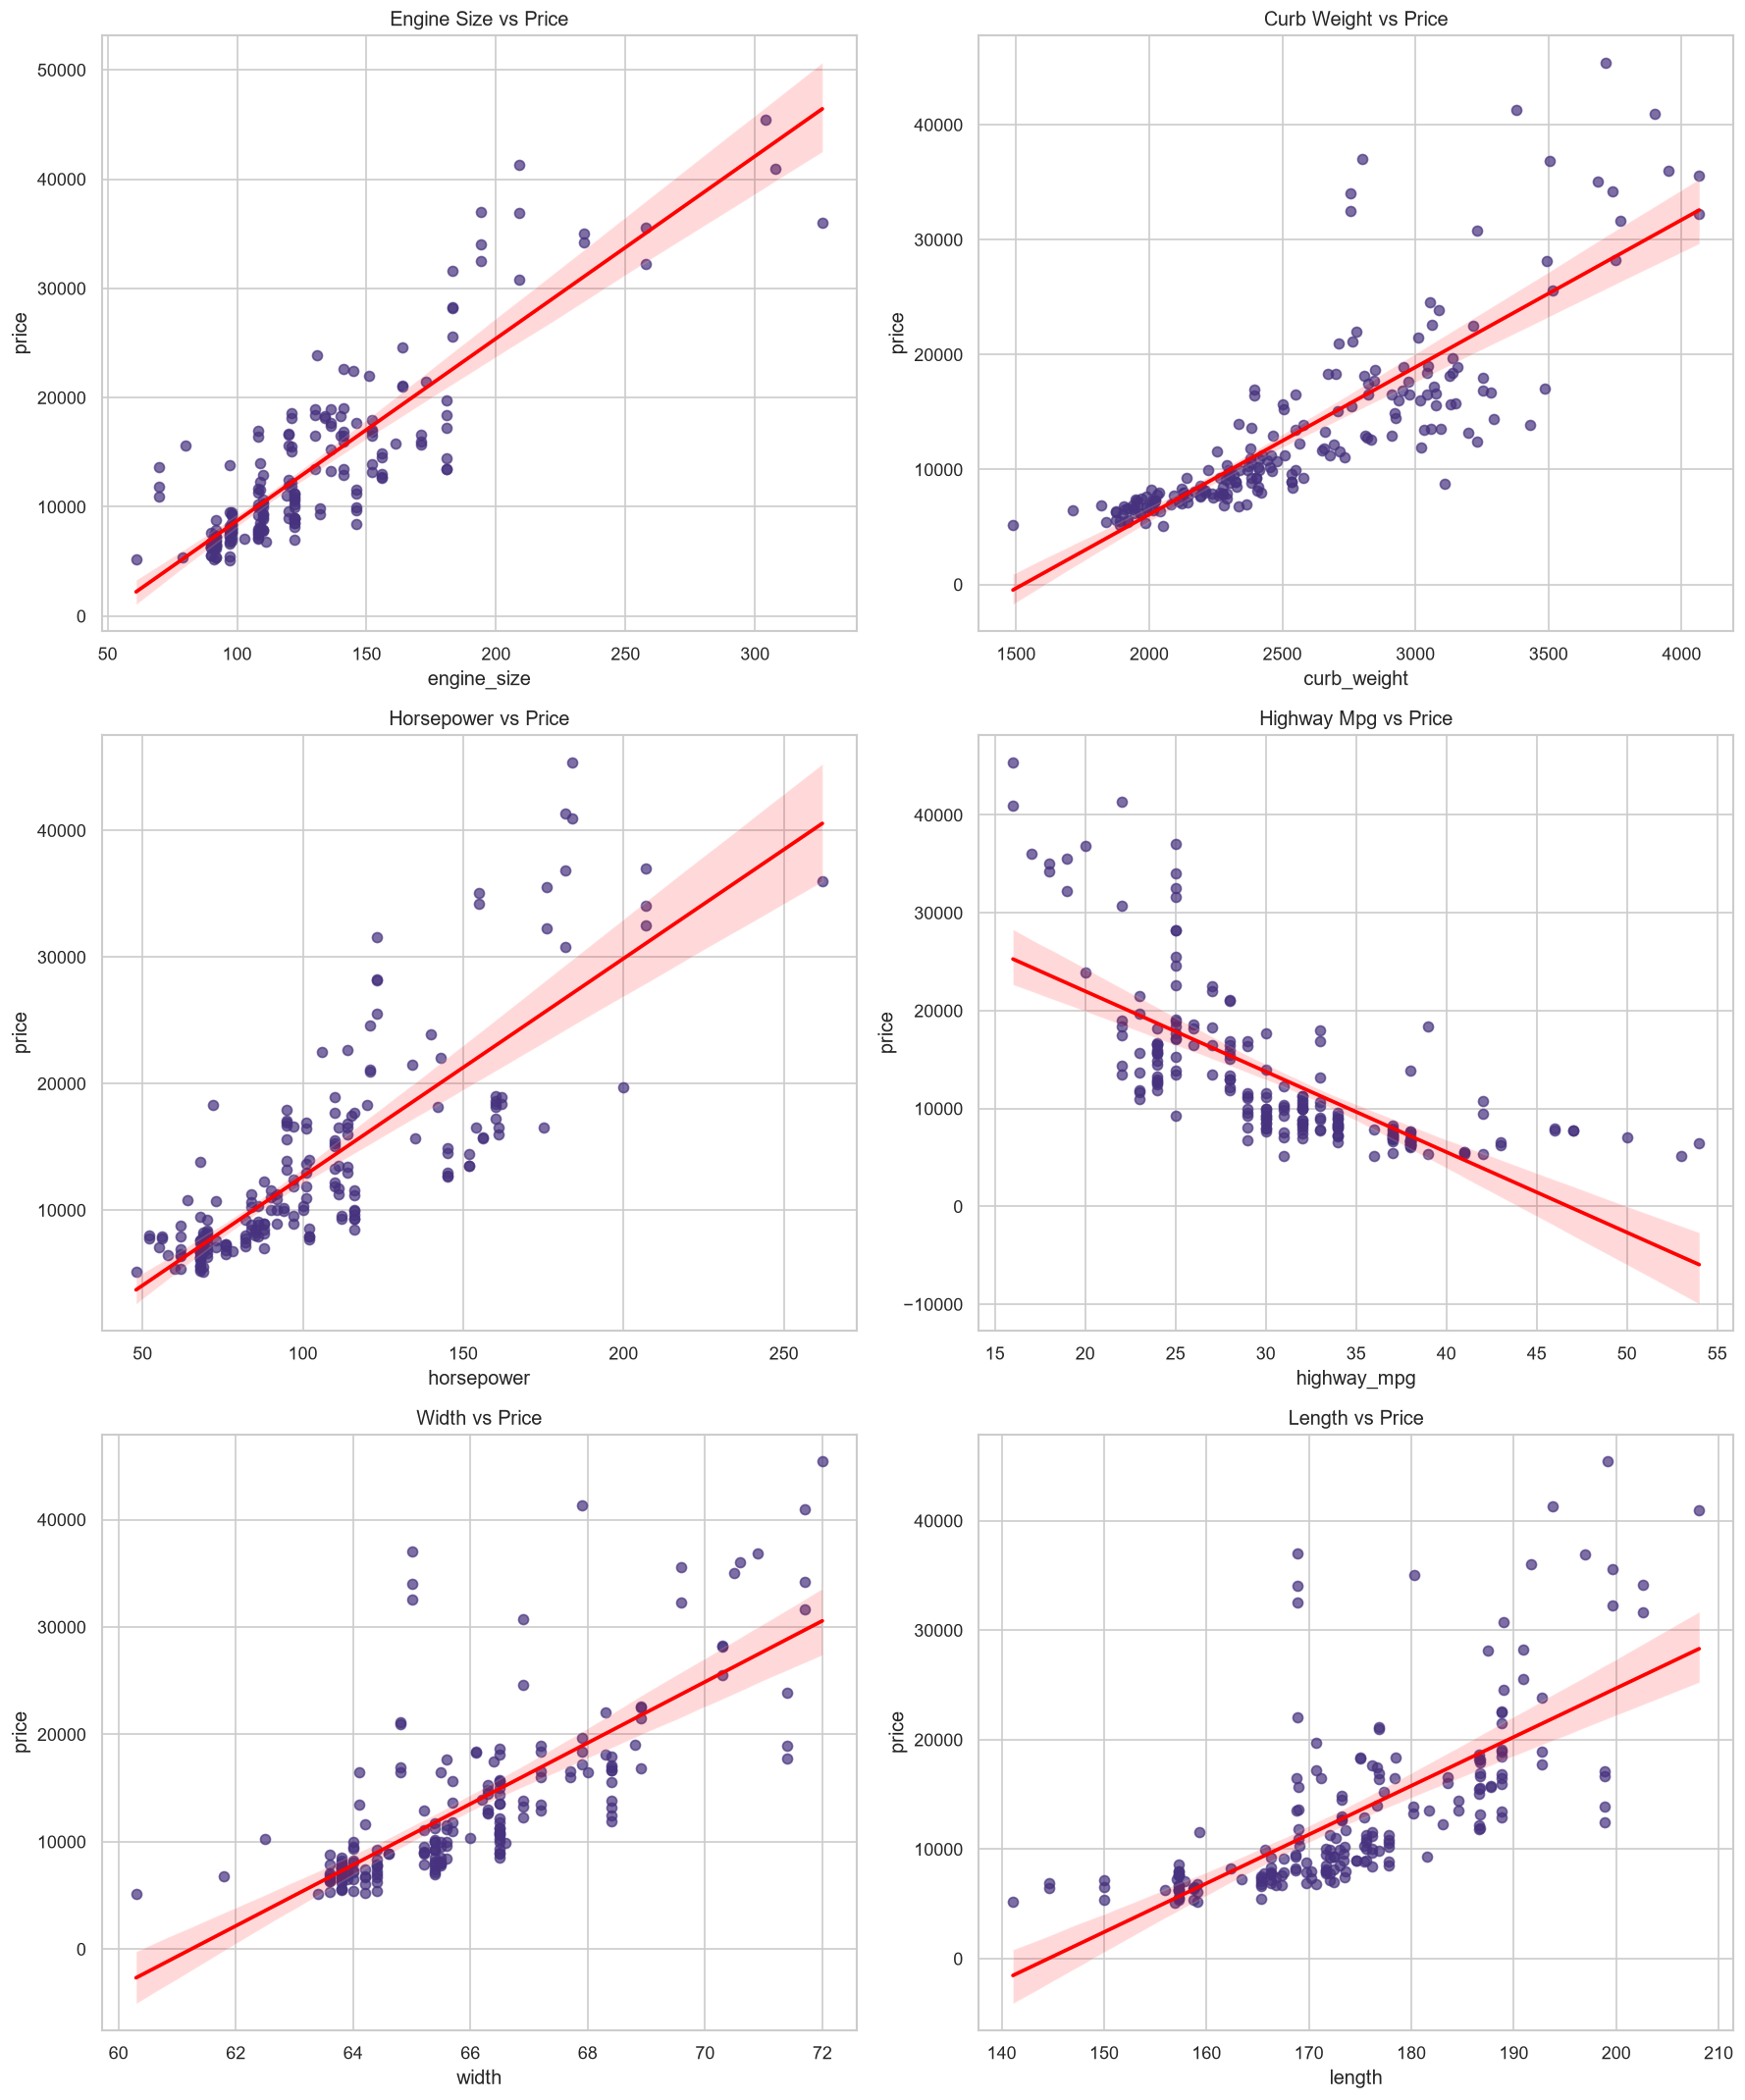

In [15]:
# Relationship between key numerical features and vehicle price

key_features = [
    "engine_size",
    "curb_weight",
    "horsepower",
    "highway_mpg",
    "width",
    "length"
]

fig, axes = plt.subplots(3, 2, figsize=(15, 18))

for feature, ax in zip(key_features, axes.flatten()):
    sns.regplot(
        data=df,
        x=feature,
        y="price",
        ax=ax,
        scatter_kws={"alpha": 0.7},
        line_kws={"color": "red"}
    )
    ax.set_title(f"{feature.replace('_', ' ').title()} vs Price")

plt.tight_layout()

plt.savefig(
    VISUALIZATION_PATH / "06_numerical_features_vs_price.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
# Spearman correlation with vehicle price

spearman_correlations = (
    df[numerical_columns]
    .corr(method="spearman")["price"]
    .drop("price")
    .sort_values(key=abs, ascending=False)
)

display(
    spearman_correlations.to_frame(
        name="Spearman_Correlation_with_Price"
    ).round(3)
)

,Spearman_Correlation_with_Price
curb_weight,0.914
horsepower,0.851
city_mpg,-0.831
engine_size,0.828
highway_mpg,-0.827
width,0.812
length,0.810
wheel_base,0.682
bore,0.649
height,0.264


In [17]:
# Compare Pearson and Spearman correlations

correlation_comparison = pd.DataFrame({
    "Pearson": df[numerical_columns].corr()["price"].drop("price"),
    "Spearman": df[numerical_columns].corr(method="spearman")["price"].drop("price")
})

correlation_comparison["Difference"] = (
    correlation_comparison["Spearman"] -
    correlation_comparison["Pearson"]
)

display(
    correlation_comparison
    .sort_values("Spearman", key=abs, ascending=False)
    .round(3)
)

,Pearson,Spearman,Difference
curb_weight,0.834,0.914,0.079
horsepower,0.811,0.851,0.040
city_mpg,-0.687,-0.831,-0.145
engine_size,0.872,0.828,-0.044
highway_mpg,-0.705,-0.827,-0.123
width,0.751,0.812,0.061
length,0.691,0.810,0.120
wheel_base,0.585,0.682,0.097
bore,0.543,0.649,0.106
height,0.135,0.264,0.128


## 9. Multicollinearity Analysis

Multicollinearity occurs when two or more independent variables are strongly related to one another.

Variance Inflation Factor (VIF) is used to examine multicollinearity among numerical features.

The analysis identifies substantial overlap among certain vehicle characteristics, particularly vehicle size, weight and fuel-efficiency variables.

This is considered during model selection. Regularised regression models and tree-based algorithms are evaluated to understand how different modelling approaches handle these relationships.

In [18]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Prepare numerical predictors
vif_data = df[numerical_columns].drop(columns=["price"]).dropna()

# Add intercept
vif_matrix = add_constant(vif_data)

# Calculate VIF
vif_results = pd.DataFrame({
    "Feature": vif_matrix.columns,
    "VIF": [
        variance_inflation_factor(vif_matrix.values, i)
        for i in range(vif_matrix.shape[1])
    ]
})

vif_results = vif_results[vif_results["Feature"] != "const"]

display(
    vif_results.sort_values("VIF", ascending=False).round(2)
)

,Feature,VIF
14,city_mpg,25.80
15,highway_mpg,23.35
7,curb_weight,16.82
8,engine_size,9.00
4,length,8.22
3,wheel_base,8.18
12,horsepower,7.23
5,width,6.09
6,height,2.73
11,compression_ratio,2.58


## 10. Exploratory Data Analysis Summary

The exploratory analysis highlights several important patterns:

- Automobile prices vary considerably across the supplied records.
- Engine size, curb weight, horsepower and vehicle dimensions show strong associations with price.
- Fuel-efficiency variables generally show negative associations with price in this dataset.
- Manufacturer and body-style groups demonstrate differences in their observed price distributions.
- Missing values and multicollinearity require appropriate preprocessing and model evaluation.

These findings guide the subsequent feature preparation and regression modelling stages.

In [19]:
# Final EDA summary for numerical features

eda_summary = pd.DataFrame({
    "Mean": df[numerical_columns].mean(),
    "Median": df[numerical_columns].median(),
    "Std_Dev": df[numerical_columns].std(),
    "Missing_Count": df[numerical_columns].isnull().sum(),
    "Pearson_Correlation": df[numerical_columns].corr()["price"],
    "Spearman_Correlation": df[numerical_columns].corr(
        method="spearman"
    )["price"]
})

display(
    eda_summary
    .drop(index="price")
    .round(3)
    .sort_values(
        "Spearman_Correlation",
        key=abs,
        ascending=False
    )
)

,Mean,Median,Std_Dev,Missing_Count,Pearson_Correlation,Spearman_Correlation
curb_weight,2555.667,2414.00,517.297,0,0.834,0.914
horsepower,103.397,95.00,37.554,2,0.811,0.851
city_mpg,25.179,24.00,6.423,0,-0.687,-0.831
engine_size,126.876,120.00,41.547,0,0.872,0.828
highway_mpg,30.687,30.00,6.815,0,-0.705,-0.827
width,65.889,65.50,2.101,0,0.751,0.812
length,174.201,173.20,12.322,0,0.691,0.810
wheel_base,98.797,97.00,6.066,0,0.585,0.682
bore,3.331,3.31,0.271,4,0.543,0.649
height,53.767,54.10,2.448,0,0.135,0.264


## 11. Feature and Target Preparation

The target variable is `price`, which represents the automobile price to be predicted.

The remaining 25 columns are treated as independent variables.

The feature matrix and target series are prepared separately to establish the inputs and expected output for supervised regression modelling.

In [20]:
# Separate features and target variable

X = df.drop(columns=["price"]).copy()
y = df["price"].copy()

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nTarget variable:")
print("Name:", y.name)
print("Missing values:", y.isnull().sum())

print("\nFeature types:")
print("Numerical features:", X.select_dtypes(include=np.number).shape[1])
print("Categorical features:", X.select_dtypes(exclude=np.number).shape[1])

print("\nMissing values in features:")
display(
    X.isnull().sum()[X.isnull().sum() > 0]
)

Feature matrix shape: (201, 25)
Target vector shape: (201,)

Target variable:
Name: price
Missing values: 0

Feature types:
Numerical features: 15
Categorical features: 10

Missing values in features:


normalized_losses    37
num_of_doors          2
bore                  4
stroke                4
horsepower            2
peak_rpm              2
dtype: int64

## 12. Training and Testing Data Split

The dataset is divided into training and testing subsets using an 80:20 split.

A fixed random state is used to make the split reproducible.

The training data is used to develop and optimise the models, while the independent test data is reserved for final performance evaluation.

In [80]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining price statistics:")
display(y_train.describe().round(2))

print("\nTesting price statistics:")
display(y_test.describe().round(2))


Training features: (160, 25)
Testing features: (41, 25)

Training target: (160,)
Testing target: (41,)

Training price statistics:


count      160.00
mean     12573.68
std       6775.93
min       5118.00
25%       7796.25
50%      10470.00
75%      16500.00
max      45400.00
Name: price, dtype: float64


Testing price statistics:


count       41.00
mean     15679.12
std      11198.46
min       5572.00
25%       7689.00
50%       9988.00
75%      18150.00
max      41315.00
Name: price, dtype: float64

## 13. Data Preprocessing

A preprocessing pipeline is developed to handle numerical and categorical variables.

Numerical features are processed using median imputation and standard scaling.

Categorical features are processed using most-frequent-value imputation and one-hot encoding.

The preprocessing steps are integrated with the machine learning models using Scikit-learn pipelines.

This approach ensures that preprocessing is fitted using training data within the cross-validation process and helps prevent data leakage.

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify feature types
numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing pipeline created successfully.")

Numerical features: 15
Categorical features: 10
Preprocessing pipeline created successfully.


In [23]:
# Fit preprocessing using training data only

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nMissing values after preprocessing:")

if hasattr(X_train_processed, "toarray"):
    print("Training:", np.isnan(X_train_processed.data).sum())
    print("Testing:", np.isnan(X_test_processed.data).sum())
else:
    print("Training:", np.isnan(X_train_processed).sum())
    print("Testing:", np.isnan(X_test_processed).sum())

print("\nPreprocessing verification completed.")

Processed training shape: (160, 74)
Processed testing shape: (41, 74)

Missing values after preprocessing:
Training: 0
Testing: 0

Preprocessing verification completed.


## 14. Baseline Model

A Dummy Regressor is developed as a baseline model.

It predicts the mean target value rather than learning relationships between vehicle characteristics and price.

The baseline provides a reference point for determining whether the machine learning models deliver meaningful improvements over a simple prediction strategy.

In [24]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Baseline model
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", DummyRegressor(strategy="mean"))
])

# Train and predict
baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_test)

# Evaluate baseline
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print("BASELINE MODEL: DUMMY REGRESSOR")
print("-" * 40)
print(f"MAE:  {baseline_mae:.2f}")
print(f"RMSE: {baseline_rmse:.2f}")
print(f"R²:   {baseline_r2:.4f}")

BASELINE MODEL: DUMMY REGRESSOR
----------------------------------------
MAE:  8262.03
RMSE: 11488.71
R²:   -0.0788


## 15. Regression Model Development

Multiple regression algorithms are evaluated to identify a suitable approach for automobile price prediction.

The evaluated algorithms include:

- Linear Regression
- Ridge Regression
- Lasso Regression
- Decision Tree Regressor
- Random Forest Regressor
- Extra Trees Regressor
- Gradient Boosting Regressor

These models represent linear, regularised linear and tree-based regression approaches.

Each model is integrated with the preprocessing pipeline.

In [25]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)

# Define candidate regression models
models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=10.0),

    "Lasso Regression": Lasso(alpha=10.0, max_iter=20000),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=5,
        min_samples_split=5,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

print("Candidate regression models:", len(models))

for model_name in models:
    print("-", model_name)

Candidate regression models: 7
- Linear Regression
- Ridge Regression
- Lasso Regression
- Decision Tree
- Random Forest
- Extra Trees
- Gradient Boosting


## 16. Cross-Validation and Model Comparison

Five-fold cross-validation is used to compare model performance across different training and validation subsets.

Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and R² are used to evaluate predictive performance.

Training and validation errors are also compared to examine generalisation gaps and identify possible overfitting.

The model with the lowest validation error is not automatically assumed to be the best production choice; its stability and independent test performance are also considered.

In [26]:
from sklearn.model_selection import KFold, cross_validate

# Five-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}

cv_results = []

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV_MAE": -scores["test_mae"].mean(),
        "CV_MAE_Std": scores["test_mae"].std(),
        "CV_RMSE": -scores["test_rmse"].mean(),
        "CV_R2": scores["test_r2"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df.sort_values("CV_MAE").round(2)
)

,Model,CV_MAE,CV_MAE_Std,CV_RMSE,CV_R2
6,Gradient Boosting,1547.92,182.09,2201.28,0.88
5,Extra Trees,1684.87,246.16,2477.75,0.86
4,Random Forest,1700.37,203.72,2460.36,0.85
1,Ridge Regression,1811.63,232.70,2579.97,0.85
2,Lasso Regression,1814.32,252.23,2703.97,0.82
0,Linear Regression,1929.24,312.42,2660.42,0.84
3,Decision Tree,2087.68,303.20,2863.64,0.79


In [27]:
# Fit each model on the complete training set

trained_models = {}
training_results = []

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", model)
    ])

    pipeline.fit(X_train, y_train)

    train_predictions = pipeline.predict(X_train)

    train_mae = mean_absolute_error(
        y_train, train_predictions
    )

    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_predictions)
    )

    train_r2 = r2_score(
        y_train, train_predictions
    )

    trained_models[name] = pipeline

    training_results.append({
        "Model": name,
        "Train_MAE": train_mae,
        "Train_RMSE": train_rmse,
        "Train_R2": train_r2
    })

training_results_df = pd.DataFrame(training_results)

model_comparison = cv_results_df.merge(
    training_results_df,
    on="Model"
)

model_comparison["MAE_Gap"] = (
    model_comparison["CV_MAE"] -
    model_comparison["Train_MAE"]
)

display(
    model_comparison.sort_values("CV_MAE").round(2)
)

,Model,CV_MAE,CV_MAE_Std,CV_RMSE,CV_R2,Train_MAE,Train_RMSE,Train_R2,MAE_Gap
6,Gradient Boosting,1547.92,182.09,2201.28,0.88,790.26,1031.48,0.98,757.67
5,Extra Trees,1684.87,246.16,2477.75,0.86,475.57,714.58,0.99,1209.30
4,Random Forest,1700.37,203.72,2460.36,0.85,730.56,1124.40,0.97,969.81
1,Ridge Regression,1811.63,232.70,2579.97,0.85,1397.53,1959.79,0.92,414.11
2,Lasso Regression,1814.32,252.23,2703.97,0.82,998.42,1311.50,0.96,815.90
0,Linear Regression,1929.24,312.42,2660.42,0.84,890.25,1179.15,0.97,1038.99
3,Decision Tree,2087.68,303.20,2863.64,0.79,1049.71,1471.01,0.95,1037.97


In [28]:
# Compare training and validation performance within identical CV folds

cv_overfit_results = []

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        return_train_score=True,
        n_jobs=-1
    )

    train_mae = -scores["train_score"].mean()
    validation_mae = -scores["test_score"].mean()

    cv_overfit_results.append({
        "Model": name,
        "CV_Train_MAE": train_mae,
        "CV_Validation_MAE": validation_mae,
        "Generalization_Gap": validation_mae - train_mae
    })

overfit_comparison = pd.DataFrame(cv_overfit_results)

display(
    overfit_comparison
    .sort_values("CV_Validation_MAE")
    .round(2)
)

,Model,CV_Train_MAE,CV_Validation_MAE,Generalization_Gap
6,Gradient Boosting,740.68,1547.92,807.24
5,Extra Trees,499.71,1684.87,1185.16
4,Random Forest,785.93,1700.37,914.44
1,Ridge Regression,1395.38,1811.63,416.25
2,Lasso Regression,930.65,1814.32,883.67
0,Linear Regression,793.94,1929.24,1135.30
3,Decision Tree,994.13,2087.68,1093.54


## 17. Hyperparameter Optimisation

RandomizedSearchCV is used to optimise selected model hyperparameters.

The search evaluates different parameter combinations using five-fold cross-validation.

Gradient Boosting, Random Forest, Extra Trees and Ridge Regression are selected for further optimisation based on their initial evaluation results.

The objective is to improve predictive performance while monitoring training and validation errors to identify potential overfitting.

In [29]:
from sklearn.model_selection import RandomizedSearchCV

# Candidate models for hyperparameter optimisation
tuning_models = {
    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=42),
        {
            "regressor__n_estimators": [100, 150, 200, 250],
            "regressor__learning_rate": [0.03, 0.05, 0.07, 0.1],
            "regressor__max_depth": [1, 2, 3],
            "regressor__min_samples_leaf": [2, 3, 5],
            "regressor__subsample": [0.8, 0.9, 1.0]
        }
    ),

    "Random Forest": (
        RandomForestRegressor(random_state=42, n_jobs=-1),
        {
            "regressor__n_estimators": [200, 300, 400],
            "regressor__max_depth": [None, 5, 8, 12],
            "regressor__min_samples_leaf": [1, 2, 3, 4],
            "regressor__max_features": [0.7, 0.9, 1.0]
        }
    ),

    "Extra Trees": (
        ExtraTreesRegressor(random_state=42, n_jobs=-1),
        {
            "regressor__n_estimators": [200, 300, 400],
            "regressor__max_depth": [None, 5, 8, 12],
            "regressor__min_samples_leaf": [1, 2, 3, 4],
            "regressor__max_features": [0.7, 0.9, 1.0]
        }
    ),

    "Ridge Regression": (
        Ridge(),
        {
            "regressor__alpha": [0.01, 0.1, 1, 5, 10, 25, 50, 100]
        }
    )
}

tuned_models = {}
tuning_results = []

for name, (model, param_grid) in tuning_models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", model)
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_grid,
        n_iter=12,
        scoring="neg_mean_absolute_error",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, y_train)

    tuned_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best_CV_MAE": -search.best_score_,
        "Best_Parameters": search.best_params_
    })

tuning_results_df = pd.DataFrame(tuning_results)

display(
    tuning_results_df.sort_values("Best_CV_MAE").reset_index(drop=True)
)

,Model,Best_CV_MAE,Best_Parameters
0,Gradient Boosting,1464.091511,"{'regressor__subsample': 0.9, 'regressor__n_es..."
1,Random Forest,1603.987644,"{'regressor__n_estimators': 200, 'regressor__m..."
2,Extra Trees,1614.129075,"{'regressor__n_estimators': 200, 'regressor__m..."
3,Ridge Regression,1794.029702,{'regressor__alpha': 5}


In [30]:
tuned_overfit_results = []

for name, pipeline in tuned_models.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        return_train_score=True,
        n_jobs=-1
    )

    train_mae = -scores["train_score"].mean()
    validation_mae = -scores["test_score"].mean()

    tuned_overfit_results.append({
        "Model": name,
        "CV_Train_MAE": train_mae,
        "CV_Validation_MAE": validation_mae,
        "Generalization_Gap": validation_mae - train_mae
    })

tuned_overfit_df = pd.DataFrame(tuned_overfit_results)

display(
    tuned_overfit_df
    .sort_values("CV_Validation_MAE")
    .round(2)
)

print("\nBest parameters for each tuned model:\n")

for name, pipeline in tuned_models.items():
    print(f"\n{name}:")
    print(pipeline.get_params()["regressor"])

,Model,CV_Train_MAE,CV_Validation_MAE,Generalization_Gap
0,Gradient Boosting,580.91,1464.09,883.18
1,Random Forest,614.97,1603.99,989.02
2,Extra Trees,73.07,1614.13,1541.06
3,Ridge Regression,1273.17,1794.03,520.86



Best parameters for each tuned model:


Gradient Boosting:
GradientBoostingRegressor(learning_rate=0.05, max_depth=2, min_samples_leaf=2,
                          n_estimators=250, random_state=42, subsample=0.9)

Random Forest:
RandomForestRegressor(max_features=0.9, n_estimators=200, n_jobs=-1,
                      random_state=42)

Extra Trees:
ExtraTreesRegressor(max_depth=12, n_estimators=200, n_jobs=-1, random_state=42)

Ridge Regression:
Ridge(alpha=5)


## 18. Final Model Evaluation

The tuned models are evaluated on the independent test dataset.

The evaluation metrics include:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² score
- Mean Absolute Percentage Error (MAPE)

These metrics provide different perspectives on prediction accuracy and model performance.

The final recommendation is based on the combined evaluation results rather than relying on a single metric.

In [31]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

final_test_results = []
test_predictions = {}

for name, model in tuned_models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    test_predictions[name] = predictions

    final_test_results.append({
        "Model": name,
        "Test_MAE": mean_absolute_error(y_test, predictions),
        "Test_RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "Test_R2": r2_score(y_test, predictions),
        "Test_MAPE_Percent": (
            mean_absolute_percentage_error(y_test, predictions) * 100
        )
    })

final_test_results_df = pd.DataFrame(final_test_results)

display(
    final_test_results_df
    .sort_values("Test_MAE")
    .round(2)
)

,Model,Test_MAE,Test_RMSE,Test_R2,Test_MAPE_Percent
0,Gradient Boosting,1506.68,2275.75,0.96,9.55
2,Extra Trees,1572.99,2610.51,0.94,9.01
1,Random Forest,1905.28,2978.94,0.93,10.45
3,Ridge Regression,2485.84,3742.38,0.89,14.92


In [32]:
# Select the leading model
final_model_name = "Gradient Boosting"
best_model = tuned_models[final_model_name]

# Create a test prediction analysis table
prediction_analysis = pd.DataFrame({
    "Actual_Price": y_test.values,
    "Predicted_Price": test_predictions[final_model_name]
})

prediction_analysis["Residual"] = (
    prediction_analysis["Actual_Price"] -
    prediction_analysis["Predicted_Price"]
)

prediction_analysis["Absolute_Error"] = (
    prediction_analysis["Residual"].abs()
)

prediction_analysis["Percentage_Error"] = (
    prediction_analysis["Absolute_Error"] /
    prediction_analysis["Actual_Price"] * 100
)

display(prediction_analysis.round(2))

print("\nLargest 10 prediction errors:")

display(
    prediction_analysis
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
    .round(2)
)

,Actual_Price,Predicted_Price,Residual,Absolute_Error,Percentage_Error
0,8249,7184.35,1064.65,1064.65,12.91
1,41315,31727.76,9587.24,9587.24,23.21
2,6855,6160.02,694.98,694.98,10.14
3,9258,7377.33,1880.67,1880.67,20.31
4,11850,13052.72,-1202.72,1202.72,10.15
5,5572,6245.06,-673.06,673.06,12.08
6,35056,33476.79,1579.21,1579.21,4.50
7,9988,10829.18,-841.18,841.18,8.42
8,15998,16884.68,-886.68,886.68,5.54
9,35550,32390.35,3159.65,3159.65,8.89



Largest 10 prediction errors:


,Actual_Price,Predicted_Price,Residual,Absolute_Error,Percentage_Error
1,41315,31727.76,9587.24,9587.24,23.21
28,37028,32420.77,4607.23,4607.23,12.44
35,11900,15903.88,-4003.88,4003.88,33.65
27,31600,27636.95,3963.05,3963.05,12.54
24,28248,24813.69,3434.31,3434.31,12.16
9,35550,32390.35,3159.65,3159.65,8.89
32,15645,13319.71,2325.29,2325.29,14.86
20,34028,32010.03,2017.97,2017.97,5.93
10,28176,26171.94,2004.06,2004.06,7.11
14,13295,15205.07,-1910.07,1910.07,14.37


## 19. Model Diagnostics and Feature Importance

The selected model is examined using diagnostic visualisations to understand its prediction performance and error patterns.

Permutation feature importance is used to estimate how much the model relies on individual features when making predictions.

The analysis helps identify the vehicle characteristics that contribute most to the model's predictive performance.

Feature importance reflects model reliance and should not be interpreted as evidence of causation.

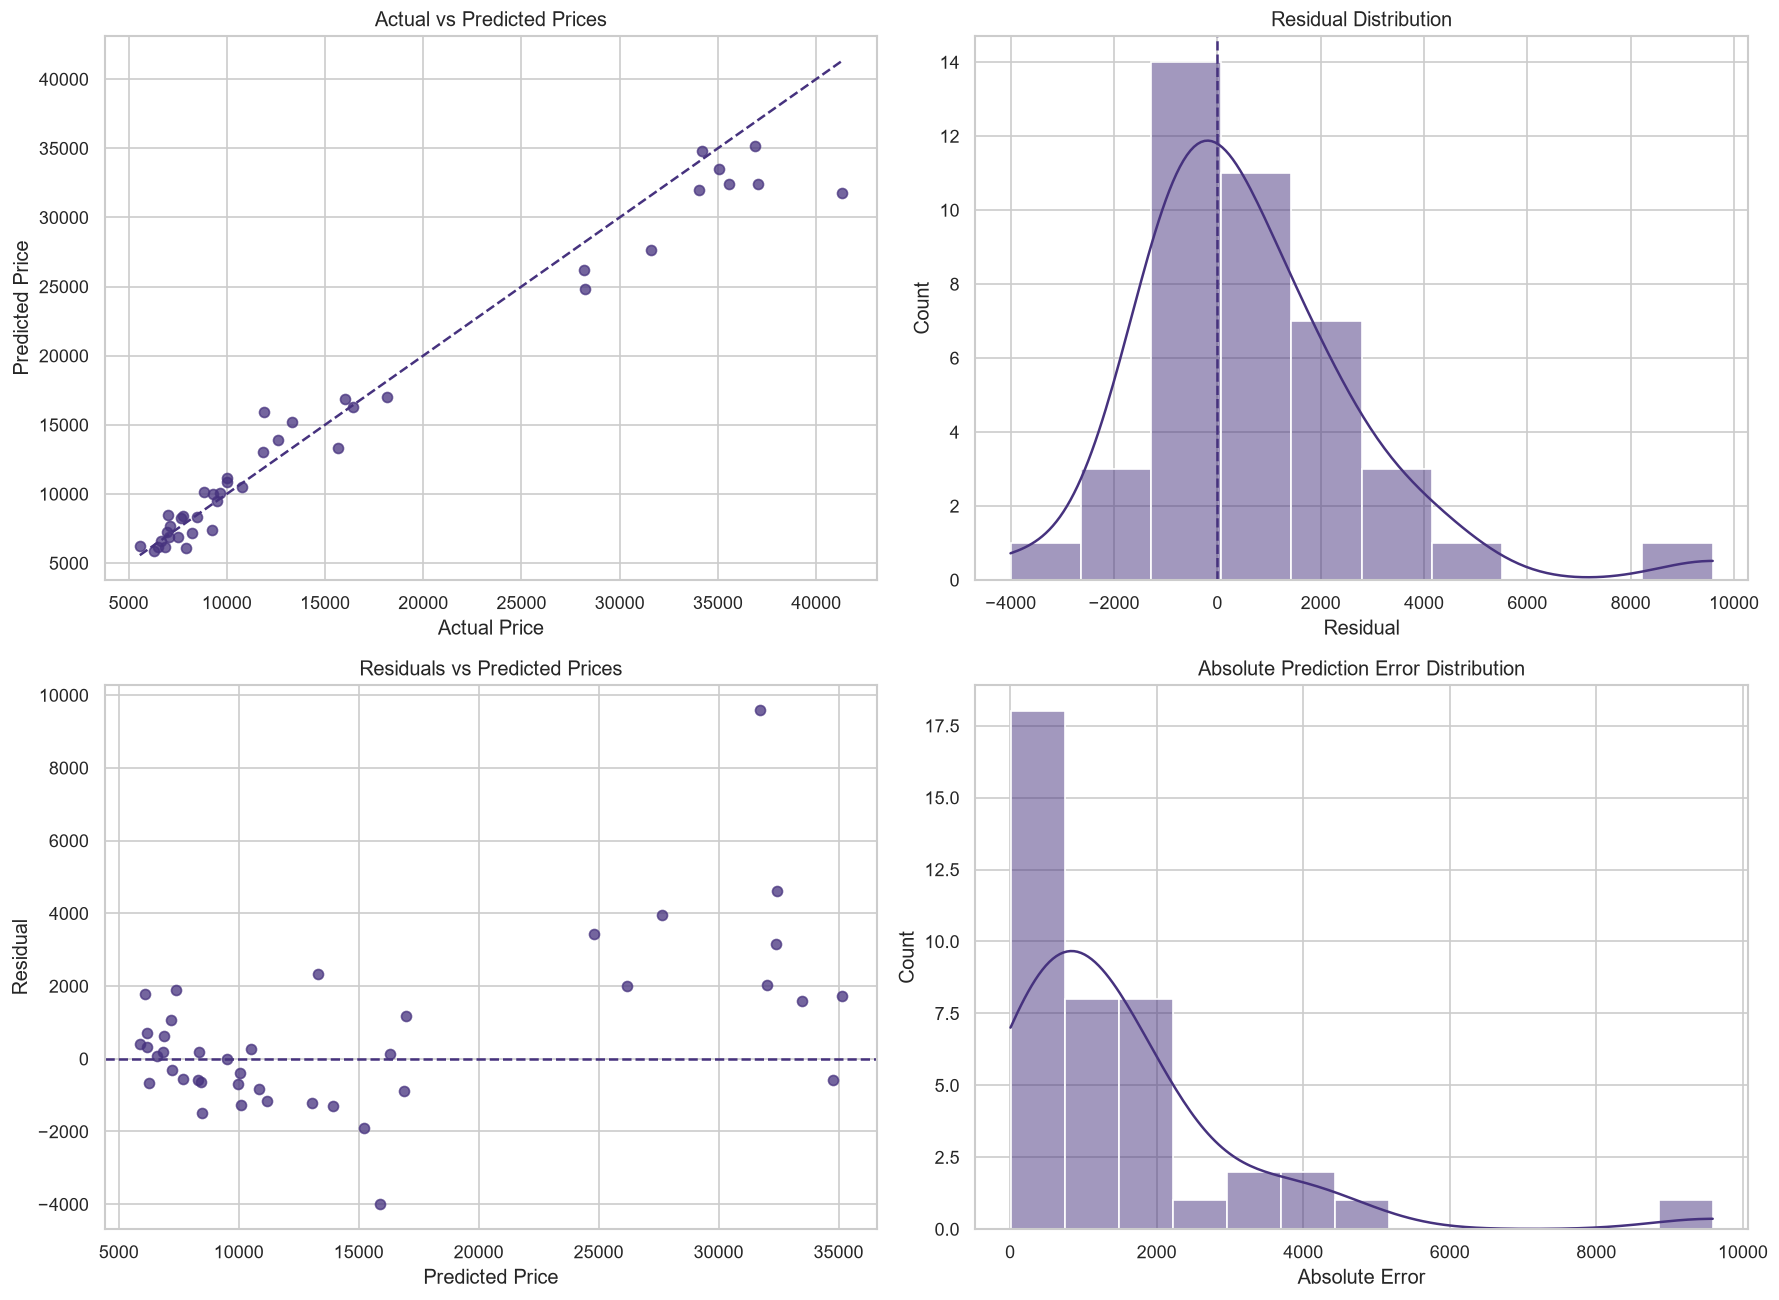

In [33]:
# Final model diagnostic visualisations

best_predictions = test_predictions["Gradient Boosting"]

residuals = y_test.values - best_predictions

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Actual vs Predicted
axes[0, 0].scatter(
    y_test, best_predictions, alpha=0.75
)

min_price = min(y_test.min(), best_predictions.min())
max_price = max(y_test.max(), best_predictions.max())

axes[0, 0].plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

axes[0, 0].set_title("Actual vs Predicted Prices")
axes[0, 0].set_xlabel("Actual Price")
axes[0, 0].set_ylabel("Predicted Price")

# 2. Residual Distribution
sns.histplot(
    residuals,
    kde=True,
    ax=axes[0, 1]
)

axes[0, 1].axvline(0, linestyle="--")
axes[0, 1].set_title("Residual Distribution")
axes[0, 1].set_xlabel("Residual")

# 3. Residuals vs Predicted
axes[1, 0].scatter(
    best_predictions, residuals, alpha=0.75
)

axes[1, 0].axhline(0, linestyle="--")
axes[1, 0].set_title("Residuals vs Predicted Prices")
axes[1, 0].set_xlabel("Predicted Price")
axes[1, 0].set_ylabel("Residual")

# 4. Absolute Prediction Errors
sns.histplot(
    prediction_analysis["Absolute_Error"],
    kde=True,
    ax=axes[1, 1]
)

axes[1, 1].set_title("Absolute Prediction Error Distribution")
axes[1, 1].set_xlabel("Absolute Error")

plt.tight_layout()

plt.savefig(
    VISUALIZATION_PATH / "07_final_model_diagnostics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
# Final Gradient Boosting performance summary

final_model_metrics = {
    "Model": "Gradient Boosting",
    "Cross_Validation_MAE": tuning_results_df.loc[
        tuning_results_df["Model"] == "Gradient Boosting",
        "Best_CV_MAE"
    ].iloc[0],
    "Test_MAE": mean_absolute_error(y_test, best_predictions),
    "Test_RMSE": np.sqrt(mean_squared_error(y_test, best_predictions)),
    "Test_R2": r2_score(y_test, best_predictions),
    "Test_MAPE_Percent": (
        mean_absolute_percentage_error(y_test, best_predictions) * 100
    )
}

final_model_summary = pd.DataFrame([final_model_metrics])

display(final_model_summary.round(2))

,Model,Cross_Validation_MAE,Test_MAE,Test_RMSE,Test_R2,Test_MAPE_Percent
0,Gradient Boosting,1464.09,1506.68,2275.75,0.96,9.55


In [35]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance on the test dataset
permutation_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

feature_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": permutation_result.importances_mean,
    "Importance_Std": permutation_result.importances_std
})

feature_importance_df = feature_importance_df.sort_values(
    "Importance_Mean",
    ascending=False
).reset_index(drop=True)

display(feature_importance_df.round(3))

,Feature,Importance_Mean,Importance_Std
0,engine_size,2469.433,293.479
1,curb_weight,1781.705,326.916
2,width,805.889,154.033
3,horsepower,588.087,78.450
4,make,455.171,88.252
5,highway_mpg,372.163,72.266
6,city_mpg,310.194,58.633
7,wheel_base,257.771,96.802
8,body_style,203.383,60.217
9,drive_wheels,105.374,32.460


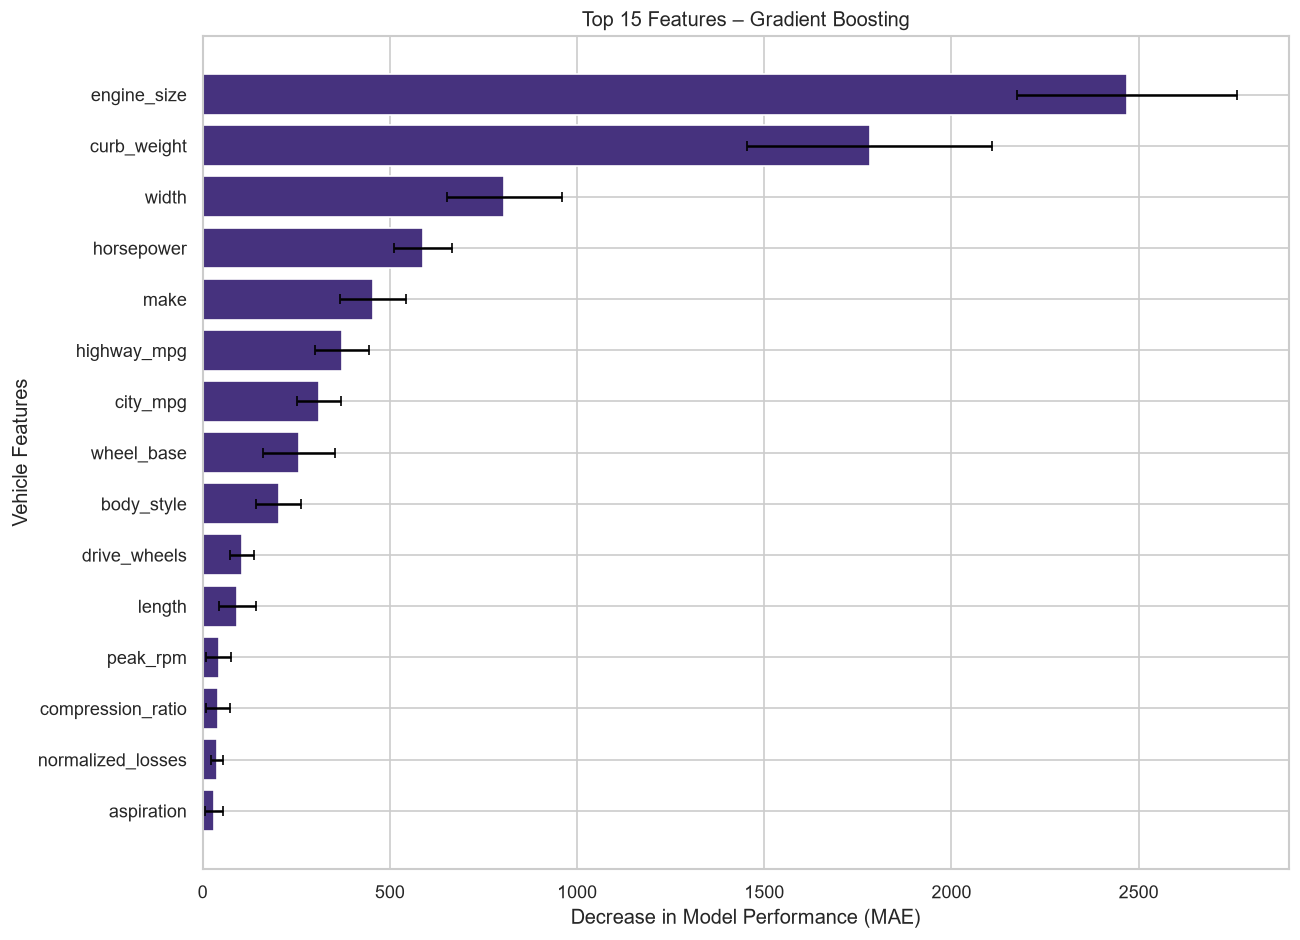

In [36]:
# Plot the top 15 features by permutation importance

top_features = feature_importance_df.head(15).sort_values(
    "Importance_Mean",
    ascending=True
)

plt.figure(figsize=(11, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance_Mean"],
    xerr=top_features["Importance_Std"],
    capsize=3
)

plt.title("Top 15 Features – Gradient Boosting")
plt.xlabel("Decrease in Model Performance (MAE)")
plt.ylabel("Vehicle Features")

plt.tight_layout()

plt.savefig(
    VISUALIZATION_PATH / "08_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 20. Model Persistence and Reusability

The selected trained model is saved using Joblib so that it can be reused without retraining.

The saved model is subsequently reloaded and tested to verify that its predictions remain consistent.

A reusable prediction function is developed to accept vehicle specifications, validate the supplied features and return a predicted automobile price.

In [37]:
import joblib

# Save the complete trained pipeline
final_model_path = MODEL_PATH / "automotive_price_prediction_model.joblib"

joblib.dump(best_model, final_model_path)

print("Final model saved successfully.")
print("Model path:", final_model_path)
print("File size:", round(final_model_path.stat().st_size / 1024, 2), "KB")

Final model saved successfully.
Model path: C:\Rakesh Project\Automotive-Price-Intelligence\models\automotive_price_prediction_model.joblib
File size: 192.82 KB


In [38]:
# Reload the saved model
loaded_model = joblib.load(final_model_path)

# Generate predictions using the reloaded model
loaded_predictions = loaded_model.predict(X_test)

# Verify predictions match the original model
predictions_match = np.allclose(
    best_predictions,
    loaded_predictions
)

print("Model reload successful:", loaded_model is not None)
print("Prediction consistency:", predictions_match)

print(
    "Reloaded model Test MAE:",
    round(mean_absolute_error(y_test, loaded_predictions), 2)
)

print(
    "Reloaded model Test R2:",
    round(r2_score(y_test, loaded_predictions), 4)
)

Model reload successful: True
Prediction consistency: True
Reloaded model Test MAE: 1506.68
Reloaded model Test R2: 0.9577


In [39]:
def predict_vehicle_price(vehicle_data, model=loaded_model):
    """
    Predict the price of a vehicle using the trained pipeline.

    Parameters:
        vehicle_data (dict): Vehicle specifications.
        model: Trained machine learning pipeline.

    Returns:
        float: Predicted vehicle price.
    """

    input_df = pd.DataFrame([vehicle_data])

    expected_columns = list(X_train.columns)

    missing_columns = set(expected_columns) - set(input_df.columns)
    extra_columns = set(input_df.columns) - set(expected_columns)

    if missing_columns or extra_columns:
        raise ValueError(
            f"Missing columns: {sorted(missing_columns)}. "
            f"Unexpected columns: {sorted(extra_columns)}."
        )

    input_df = input_df[expected_columns]

    predicted_price = model.predict(input_df)[0]

    return round(float(predicted_price), 2)


print("Prediction function created successfully.")

Prediction function created successfully.


In [40]:
# Select one vehicle from the original dataset
sample_vehicle = X.iloc[[0]].iloc[0].to_dict()

# Predict its price
sample_prediction = predict_vehicle_price(sample_vehicle)

print("Actual Vehicle Price:", y.iloc[0])
print("Predicted Vehicle Price:", sample_prediction)

Actual Vehicle Price: 13495
Predicted Vehicle Price: 15543.0


In [41]:
# Test with an intentionally incomplete vehicle record

invalid_vehicle = {
    "make": "toyota",
    "fuel_type": "gas"
}

try:
    predict_vehicle_price(invalid_vehicle)

except ValueError as error:
    print("Input validation successful.")
    print("Error:", error)

Input validation successful.
Error: Missing columns: ['aspiration', 'body_style', 'bore', 'city_mpg', 'compression_ratio', 'curb_weight', 'drive_wheels', 'engine_location', 'engine_size', 'engine_type', 'fuel_system', 'height', 'highway_mpg', 'horsepower', 'length', 'normalized_losses', 'num_of_cylinders', 'num_of_doors', 'peak_rpm', 'stroke', 'symboling', 'wheel_base', 'width']. Unexpected columns: [].


## 21. Production Prediction Module

The prediction functionality is organised into a separate Python module under the `src` directory.

The module supports model loading, input validation and vehicle price prediction.

Separating prediction functionality from the notebook makes the trained model easier to reuse in other Python applications.

In [42]:
predict_file = PROJECT_ROOT / "src" / "predict.py"

predict_code = '''from pathlib import Path

import joblib
import pandas as pd


MODEL_PATH = (
    Path(__file__).resolve().parents[1]
    / "models"
    / "automotive_price_prediction_model.joblib"
)


def load_model():
    """Load the saved vehicle price prediction model."""
    if not MODEL_PATH.exists():
        raise FileNotFoundError(f"Model file not found: {MODEL_PATH}")

    return joblib.load(MODEL_PATH)


def predict_vehicle_price(vehicle_data, model=None):
    """
    Predict vehicle price from a dictionary or a single-row DataFrame.
    """

    if isinstance(vehicle_data, dict):
        input_df = pd.DataFrame([vehicle_data])
    elif isinstance(vehicle_data, pd.DataFrame):
        input_df = vehicle_data.copy()
    else:
        raise TypeError("Input must be a dictionary or pandas DataFrame.")

    if len(input_df) != 1:
        raise ValueError("Please provide exactly one vehicle record.")

    if model is None:
        model = load_model()

    expected_columns = list(model.feature_names_in_)

    missing_columns = set(expected_columns) - set(input_df.columns)
    extra_columns = set(input_df.columns) - set(expected_columns)

    if missing_columns or extra_columns:
        raise ValueError(
            f"Missing columns: {sorted(missing_columns)}. "
            f"Unexpected columns: {sorted(extra_columns)}."
        )

    input_df = input_df[expected_columns]

    predicted_price = float(model.predict(input_df)[0])

    return round(predicted_price, 2)
'''

predict_file.write_text(predict_code, encoding="utf-8")

print("Prediction module created:", predict_file)
print("File exists:", predict_file.exists())

Prediction module created: C:\Rakesh Project\Automotive-Price-Intelligence\src\predict.py
File exists: True


In [43]:
import sys

sys.path.insert(0, str(PROJECT_ROOT / "src"))

from predict import predict_vehicle_price as production_predict

# Predict using the production module
production_prediction = production_predict(sample_vehicle)

print("Notebook prediction:", sample_prediction)
print("Production module prediction:", production_prediction)
print(
    "Predictions match:",
    np.isclose(sample_prediction, production_prediction)
)

Notebook prediction: 15543.0
Production module prediction: 15543.0
Predictions match: True


## 22. Automated Testing

Pytest is used to validate the reusable prediction module.

The test suite checks:

- Successful predictions using valid vehicle features.
- Error handling when required features are missing.
- Error handling when the supplied input has an invalid data type.

All three tests passed during project verification.

In [44]:
test_file = PROJECT_ROOT / "tests" / "test_prediction.py"

test_code = '''import sys
from pathlib import Path

import pytest

PROJECT_ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from predict import predict_vehicle_price


def get_valid_vehicle():
    return {
        "symboling": 3,
        "normalized_losses": 122,
        "make": "alfa-romero",
        "fuel_type": "gas",
        "aspiration": "std",
        "num_of_doors": "two",
        "body_style": "convertible",
        "drive_wheels": "rwd",
        "engine_location": "front",
        "wheel_base": 88.6,
        "length": 168.8,
        "width": 64.1,
        "height": 48.8,
        "curb_weight": 2548,
        "engine_type": "dohc",
        "num_of_cylinders": "four",
        "engine_size": 130,
        "fuel_system": "mpfi",
        "bore": 3.47,
        "stroke": 2.68,
        "compression_ratio": 9.0,
        "horsepower": 111,
        "peak_rpm": 5000,
        "city_mpg": 21,
        "highway_mpg": 27
    }


def test_valid_vehicle_prediction():
    prediction = predict_vehicle_price(get_valid_vehicle())

    assert isinstance(prediction, float)
    assert prediction > 0


def test_missing_features_raise_error():
    invalid_vehicle = {
        "make": "toyota",
        "fuel_type": "gas"
    }

    with pytest.raises(ValueError, match="Missing columns"):
        predict_vehicle_price(invalid_vehicle)


def test_invalid_input_type_raises_error():
    with pytest.raises(TypeError):
        predict_vehicle_price("invalid input")
'''

test_file.write_text(test_code, encoding="utf-8")

print("Test file created:", test_file)
print("File exists:", test_file.exists())

Test file created: C:\Rakesh Project\Automotive-Price-Intelligence\tests\test_prediction.py
File exists: True


In [45]:
import subprocess
import sys

test_result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        str(PROJECT_ROOT / "tests" / "test_prediction.py"),
        "-v"
    ],
    capture_output=True,
    text=True
)

print(test_result.stdout)

if test_result.stderr:
    print(test_result.stderr)

print("Pytest exit code:", test_result.returncode)

============================= test session starts =============================
platform win32 -- Python 3.13.17, pytest-9.2.0, pluggy-1.7.0 -- C:\Rakesh Project\Automotive-Price-Intelligence\.venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\Rakesh Project\Automotive-Price-Intelligence
plugins: anyio-4.16.0, platformdirs-4.14.5
collecting ... collected 3 items

..\tests\test_prediction.py::test_valid_vehicle_prediction PASSED        [ 33%]
..\tests\test_prediction.py::test_missing_features_raise_error PASSED    [ 66%]
..\tests\test_prediction.py::test_invalid_input_type_raises_error PASSED [100%]

============================== 3 passed in 2.16s ==============================

Pytest exit code: 0


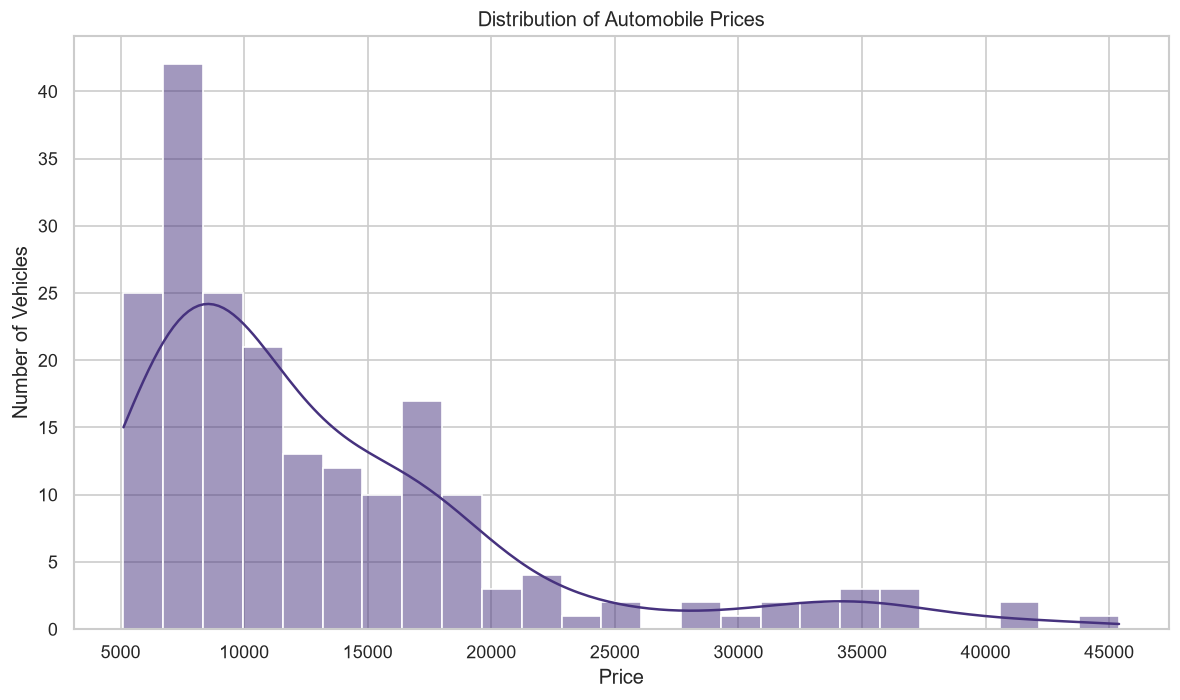

Price distribution saved: C:\Rakesh Project\Automotive-Price-Intelligence\visualizations\09_price_distribution.png
File exists: True


In [46]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["price"],
    bins=25,
    kde=True
)

plt.title("Distribution of Automobile Prices")
plt.xlabel("Price")
plt.ylabel("Number of Vehicles")
plt.tight_layout()

price_plot_path = VISUALIZATION_PATH / "09_price_distribution.png"

plt.savefig(price_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Price distribution saved:", price_plot_path)
print("File exists:", price_plot_path.exists())

## 23. Supporting Reports and Project Documentation

Additional project deliverables are generated to document the modelling process and support project reproducibility.

These include:

- Model Comparison Report.
- Challenges Faced Report.
- Requirements file.
- Git ignore configuration.
- Project README.

The supporting documentation summarises the project methodology, model performance, challenges, limitations and recommended model.

In [47]:
model_report = """# Automotive Price Intelligence & Prediction
## Model Comparison Report

### 1. Objective

The objective was to compare multiple regression algorithms to predict automobile prices using 25 vehicle attributes. The models were evaluated using five-fold cross-validation, hyperparameter tuning and an independent test dataset.

### 2. Baseline Model

A Dummy Regressor using the training-set mean was used as the baseline.

| Metric | Baseline Result |
|---|---:|
| Test MAE | 8262.03 |
| Test RMSE | 11488.71 |
| Test R² | -0.0788 |

The negative R² indicates that the baseline performed poorly on the test dataset.

### 3. Initial Model Comparison

Five-fold cross-validation results before hyperparameter tuning:

| Model | CV Validation MAE | CV MAE Std | CV RMSE | CV R² |
|---|---:|---:|---:|---:|
| Gradient Boosting | 1547.92 | 182.09 | 2201.28 | 0.88 |
| Extra Trees | 1684.87 | 246.16 | 2477.75 | 0.86 |
| Random Forest | 1700.37 | 203.72 | 2460.36 | 0.85 |
| Ridge Regression | 1811.63 | 232.70 | 2579.97 | 0.85 |
| Lasso Regression | 1814.32 | 252.23 | 2703.97 | 0.82 |
| Linear Regression | 1929.24 | 312.42 | 2660.42 | 0.84 |
| Decision Tree | 2087.68 | 303.20 | 2863.64 | 0.79 |

Gradient Boosting achieved the lowest validation MAE among the initial candidate models.

### 4. Hyperparameter Tuning

RandomizedSearchCV was used with five-fold cross-validation and 12 parameter combinations per candidate model.

| Model | Best CV MAE |
|---|---:|
| Gradient Boosting | 1464.09 |
| Random Forest | 1603.99 |
| Extra Trees | 1614.13 |
| Ridge Regression | 1794.03 |

The tuned Gradient Boosting model used:
- n_estimators: 250
- learning_rate: 0.05
- max_depth: 2
- min_samples_leaf: 2
- subsample: 0.9
- random_state: 42

### 5. Final Test-Set Comparison

The tuned models were evaluated on the independent test set containing 41 records.

| Model | Test MAE | Test RMSE | Test R² | Test MAPE |
|---|---:|---:|---:|---:|
| Gradient Boosting | 1506.68 | 2275.75 | 0.96 | 9.55% |
| Extra Trees | 1572.99 | 2610.51 | 0.94 | 9.01% |
| Random Forest | 1905.28 | 2978.94 | 0.93 | 10.45% |
| Ridge Regression | 2485.84 | 3742.38 | 0.89 | 14.92% |

### 6. Production Model Recommendation

**Recommended model: Tuned Gradient Boosting Regressor**

Reasons:
- Lowest test MAE among the tuned models.
- Lowest test RMSE among the tuned models.
- Highest test R².
- Strong five-fold cross-validation performance.
- Lower prediction error than the other evaluated models on the independent test set.

Extra Trees achieved a slightly lower MAPE, but Gradient Boosting performed better on MAE, RMSE and R². Therefore, Gradient Boosting is selected as the primary model based on the overall evaluation.

### 7. Generalisation and Limitations

The tuned Gradient Boosting model recorded a cross-validation training MAE of 580.91 and validation MAE of 1464.09, giving a generalisation gap of 883.18. This indicates some difference between training and validation performance.

The independent test set contains only 41 records. Results should therefore be interpreted with caution. The dataset represents historical automobile imports from the 1980s and does not establish accuracy for today's automobile market.

External validation on a larger, more recent and representative dataset is recommended before commercial deployment.

### 8. Conclusion

Gradient Boosting provided the strongest overall predictive performance among the evaluated tuned models. It was saved as the final model and its reloaded predictions were verified against the original model predictions.
"""

model_report_path = REPORT_PATH / "model_comparison_report.md"
model_report_path.write_text(model_report, encoding="utf-8")

print("Model comparison report created:", model_report_path)
print("File exists:", model_report_path.exists())
print("Report size:", round(model_report_path.stat().st_size / 1024, 2), "KB")

Model comparison report created: C:\Rakesh Project\Automotive-Price-Intelligence\reports\model_comparison_report.md
File exists: True
Report size: 3.57 KB


In [48]:
challenges_report = """# Automotive Price Intelligence & Prediction
## Challenges Faced Report

### 1. Dataset Size and Source Differences

**Challenge:**
The supplied CSV contained 201 records and 26 attributes, while the accompanying dataset documentation described 205 instances.

**Solution:**
The actual supplied CSV was treated as the source of truth for implementation. Its dimensions and column structure were verified independently.

**Reason:**
Using the actual supplied data avoids making assumptions about records that were not present.

### 2. Missing Values

**Challenge:**
The dataset contained 51 missing entries across six attributes:
- normalized_losses: 37
- num_of_doors: 2
- bore: 4
- stroke: 4
- horsepower: 2
- peak_rpm: 2

The target variable, price, had no missing values in the supplied CSV.

**Solution:**
Median imputation was used for numerical features, and most-frequent-value imputation was used for categorical features.

**Reason:**
Median imputation is less sensitive to extreme numerical values than mean imputation. Most-frequent-value imputation preserves valid categorical values without introducing artificial categories.

### 3. Mixed Data Types

**Challenge:**
The dataset contained both numerical and categorical variables.

**Solution:**
A ColumnTransformer was used to apply separate preprocessing:
- Numerical features: median imputation and StandardScaler.
- Categorical features: most-frequent imputation and OneHotEncoder with handle_unknown="ignore".

**Reason:**
Regression algorithms require numerical input. One-hot encoding represents categories without imposing an artificial numerical order. Scaling helps scale-sensitive algorithms.

### 4. Potential Outliers

**Challenge:**
IQR analysis identified potential outliers, including 14 high-priced vehicles above the upper price threshold of 29,587.50.

**Solution:**
The high-priced observations were investigated and retained because their specifications were plausible for premium and high-performance vehicles.

**Reason:**
Removing valid luxury vehicles could distort the target distribution and reduce the model's ability to predict higher-priced cars.

### 5. Multicollinearity

**Challenge:**
VIF analysis identified relationships among vehicle dimensions, engine characteristics and fuel-efficiency variables. For example, city_mpg had a VIF of 25.80 and highway_mpg had a VIF of 23.35.

**Solution:**
Multiple model families were evaluated, including Ridge and Lasso regression, tree-based models and ensemble methods.

**Reason:**
Regularised regression can help manage correlated predictors, while tree-based models can capture nonlinear relationships. Features were not removed solely because of high VIF values.

### 6. Nonlinear Relationships

**Challenge:**
The relationship between vehicle specifications and price was not necessarily linear. Different manufacturers, engine configurations and vehicle characteristics can interact.

**Solution:**
Linear regression models were compared with Decision Tree, Random Forest, Extra Trees and Gradient Boosting models.

**Reason:**
Comparing different algorithm families helps identify whether more flexible nonlinear models provide better predictive performance.

### 7. Overfitting and Generalisation

**Challenge:**
Some models showed large differences between training and validation errors. Extra Trees, in particular, showed a large generalisation gap after tuning.

**Solution:**
Five-fold cross-validation, train-validation MAE comparison, hyperparameter tuning and an independent test set were used.

**Reason:**
These methods provide a more reliable assessment of model performance and help identify models that fit training data too closely.

### 8. Small Test Dataset

**Challenge:**
The dataset contained only 201 records, leaving 41 observations in the independent test set after the 80:20 split.

**Solution:**
A fixed random state of 42 was used for reproducibility, and five-fold cross-validation was used during model evaluation and tuning.

**Reason:**
Cross-validation makes better use of the limited training data. However, a small holdout set still introduces uncertainty into performance estimates.

### 9. Model Persistence and Prediction Validation

**Challenge:**
A trained model must be reusable outside the notebook and should reject incomplete input.

**Solution:**
The complete preprocessing and prediction pipeline was saved using Joblib. A separate Python prediction module and automated pytest tests were created.

**Reason:**
Saving the complete pipeline ensures that new data receives the same preprocessing as training data. Input validation prevents incomplete or unexpected records from being passed to the model.

### 10. Historical Dataset Limitations

**Challenge:**
The dataset represents automobile imports from the 1980s and contains a limited number of observations.

**Solution:**
The project documents the historical scope of the dataset and recommends validation with larger and more recent data before real-world commercial use.

**Reason:**
Strong performance on this dataset does not establish that the model can accurately predict prices in today's automobile market.

### 11. Conclusion

The project addressed missing data, mixed feature types, potential outliers, multicollinearity, nonlinear relationships, overfitting and limited dataset size through structured exploratory analysis, preprocessing pipelines, cross-validation, model comparison and automated testing.

The selected Gradient Boosting model demonstrated the strongest overall test-set performance among the tuned candidates. Its limitations have also been documented to ensure that the results are interpreted responsibly.
"""

challenges_report_path = REPORT_PATH / "challenges_faced_report.md"
challenges_report_path.write_text(challenges_report, encoding="utf-8")

print("Challenges report created:", challenges_report_path)
print("File exists:", challenges_report_path.exists())
print("Report size:", round(challenges_report_path.stat().st_size / 1024, 2), "KB")

Challenges report created: C:\Rakesh Project\Automotive-Price-Intelligence\reports\challenges_faced_report.md
File exists: True
Report size: 5.68 KB


In [49]:
requirements = """pandas==3.1.1
numpy==2.5.4
matplotlib==3.11.2
seaborn==0.13.2
scikit-learn==1.9.1
scipy==1.18.1
statsmodels==0.15.0
joblib==1.6.0
pytest==9.2.0
jupyter==1.1.1
ipykernel==7.4.0
"""

requirements_path = PROJECT_ROOT / "requirements.txt"
requirements_path.write_text(requirements, encoding="utf-8")

print("Requirements file created:", requirements_path)
print("File exists:", requirements_path.exists())

Requirements file created: C:\Rakesh Project\Automotive-Price-Intelligence\requirements.txt
File exists: True


In [51]:
gitignore_content = """# Virtual environments
.venv/
venv/
env/

# Python cache
__pycache__/
*.py[cod]

# Jupyter temporary files
.ipynb_checkpoints/

# Testing and coverage
.pytest_cache/
.coverage
htmlcov/

# Local environment and secrets
.env
.env.*

# Operating system files
.DS_Store
Thumbs.db
"""

gitignore_path.write_text(gitignore_content, encoding="utf-8")

print("Updated .gitignore successfully.")
print(gitignore_path.read_text(encoding="utf-8"))

Updated .gitignore successfully.
# Virtual environments
.venv/
venv/
env/

# Python cache
__pycache__/
*.py[cod]

# Jupyter temporary files
.ipynb_checkpoints/

# Testing and coverage
.pytest_cache/
.coverage
htmlcov/

# Local environment and secrets
.env
.env.*

# Operating system files
.DS_Store
Thumbs.db



## 24. Project README

The README provides an overview of the project, its objectives, dataset, technologies, machine learning approach, model performance and project structure.

It also explains how to install the dependencies, execute the notebook, use the prediction module and run the automated tests.

In [53]:
readme_path = PROJECT_ROOT / "README.md"

print("README file already exists:", readme_path.exists())

README file already exists: False


In [55]:
readme_content = """# Automotive Price Intelligence & Prediction

## Project Overview

Automotive Price Intelligence & Prediction is a machine learning project developed to analyse automobile characteristics and predict vehicle prices using historical automobile import data.

The project explores the relationship between vehicle specifications and pricing, compares multiple regression algorithms, and identifies a suitable predictive model.

"""

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme_content)

print("Project title and overview added successfully.")

Project title and overview added successfully.


In [56]:
objectives = """## Project Objectives

- Perform exploratory data analysis on automobile specifications.
- Identify important factors associated with vehicle prices.
- Handle missing values and prepare numerical and categorical features.
- Train and compare multiple regression algorithms.
- Optimise model hyperparameters using cross-validation.
- Evaluate model performance on an independent test dataset.
- Develop a reusable prediction module.
- Document modelling challenges and business insights.

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(objectives)

print("Project objectives added successfully.")

Project objectives added successfully.


In [57]:
dataset_section = """## Dataset

- Source: 1985 Auto Imports Database.
- Records supplied: 201.
- Attributes: 26.
- Independent variables: 25.
- Target variable: `price`.

The supplied dataset contains missing values in several independent variables. No target prices were missing.

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(dataset_section)

print("Dataset information added successfully.")

Dataset information added successfully.


In [58]:
technology_section = """## Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- SciPy
- Statsmodels
- Joblib
- Jupyter Notebook
- Pytest

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(technology_section)

print("Technologies section added successfully.")

Technologies section added successfully.


In [59]:
models_section = """## Machine Learning Models

The following regression algorithms were evaluated:

1. Dummy Regressor (baseline)
2. Linear Regression
3. Ridge Regression
4. Lasso Regression
5. Decision Tree Regressor
6. Random Forest Regressor
7. Extra Trees Regressor
8. Gradient Boosting Regressor

Hyperparameter optimisation was performed using RandomizedSearchCV with five-fold cross-validation.

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(models_section)

print("Machine learning models section added successfully.")

Machine learning models section added successfully.


In [60]:
performance_section = """## Final Model Performance

The tuned Gradient Boosting model was selected as the recommended model.

| Metric | Result |
|---|---:|
| Cross-validation MAE | 1464.09 |
| Test MAE | 1506.68 |
| Test RMSE | 2275.75 |
| Test R² | 0.9577 |
| Test MAPE | 9.55% |

The independent test dataset contained 41 records.

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(performance_section)

print("Final model performance section added successfully.")

Final model performance section added successfully.


In [61]:
findings_section = """## Key Findings

- Engine size, curb weight, vehicle width and horsepower were among the most important features for the selected model.
- Vehicle characteristics showed different relationships with price.
- Premium and high-performance vehicles formed part of the higher-priced observations.
- Gradient Boosting achieved the strongest overall test-set performance among the tuned models.

Feature importance describes model reliance on predictors and should not be interpreted as proof of causation.

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(findings_section)

print("Key findings section added successfully.")

Key findings section added successfully.


In [63]:
structure_section = """## Project Structure

Automotive-Price-Intelligence/
|
|-- data/
|   |-- raw/
|   |-- processed/
|
|-- notebooks/
|   |-- Automotive_Price_Intelligence_and_Prediction.ipynb
|
|-- src/
|   |-- predict.py
|
|-- models/
|   |-- automotive_price_prediction_model.joblib
|
|-- visualizations/
|
|-- reports/
|   |-- model_comparison_report.md
|   |-- challenges_faced_report.md
|
|-- tests/
|   |-- test_prediction.py
|
|-- documentation/
|
|-- requirements.txt
|-- .gitignore
|-- README.md

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(structure_section)

print("Project structure section added successfully.")

Project structure section added successfully.


In [64]:
installation_section = """## Installation

Clone the repository and navigate to the project directory.

Create a virtual environment:

    python -m venv .venv

Activate the environment in Windows PowerShell:

    .venv\\Scripts\\Activate.ps1

Install the required dependencies:

    pip install -r requirements.txt

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(installation_section)

print("Installation instructions added successfully.")

Installation instructions added successfully.


In [65]:
notebook_section = """## Running the Notebook

Start Jupyter Notebook:

    jupyter notebook

Open the following notebook:

    notebooks/Automotive_Price_Intelligence_and_Prediction.ipynb

Select the appropriate Python environment and execute the notebook cells in order.

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(notebook_section)

print("Notebook instructions added successfully.")

Notebook instructions added successfully.


In [66]:
prediction_section = """## Making a Prediction

The reusable prediction module is located at:

    src/predict.py

Example usage:

    from predict import predict_vehicle_price

    vehicle = {
        # Supply all 25 required vehicle features.
    }

    predicted_price = predict_vehicle_price(vehicle)
    print(predicted_price)

The prediction function validates the supplied feature names and loads the saved model automatically.

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(prediction_section)

print("Prediction instructions added successfully.")

Prediction instructions added successfully.


In [67]:
testing_section = """## Automated Testing

Run the tests from the project root:

    python -m pytest tests/ -v

The current test suite covers:

- Valid vehicle predictions.
- Missing feature validation.
- Invalid input type validation.

All three tests passed during project verification.

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(testing_section)

print("Automated testing section added successfully.")

Automated testing section added successfully.


In [68]:
reports_section = """## Reports and Visualisations

The reports directory contains:

- Model Comparison Report.
- Challenges Faced Report.

The visualizations directory contains exploratory data analysis plots, feature importance analysis and final model diagnostic plots.

These visualisations cover:

- Correlation analysis.
- Manufacturer distribution.
- Categorical feature analysis against price.
- Numerical feature distributions.
- Missing value analysis.
- Numerical features against price.
- Final model diagnostics.
- Feature importance.
- Automobile price distribution.

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(reports_section)

print("Reports and visualisations section added successfully.")

Reports and visualisations section added successfully.


In [69]:
limitations_section = """## Limitations

- The dataset is small, containing only 201 supplied records.
- It represents historical automobile imports from the 1980s.
- The independent test set contains only 41 records.
- Results do not establish prediction accuracy for modern automobile markets.
- External validation using larger and more recent datasets is recommended before commercial deployment.

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(limitations_section)

print("Project limitations section added successfully.")

Project limitations section added successfully.


In [70]:
conclusion_section = """## Conclusion

The project demonstrates an end-to-end machine learning workflow covering exploratory data analysis, data preprocessing, model comparison, hyperparameter optimisation, model evaluation, model persistence, reusable prediction functionality and automated testing.

The tuned Gradient Boosting model demonstrated the strongest overall performance among the evaluated tuned candidates on the independent test dataset.

"""

with open(readme_path, "a", encoding="utf-8") as file:
    file.write(conclusion_section)

print("Project conclusion added successfully.")

Project conclusion added successfully.


In [72]:
readme_content = readme_path.read_text(encoding="utf-8")

readme_content = readme_content.replace(
    "from predict import predict_vehicle_price",
    "from src.predict import predict_vehicle_price"
)

readme_path.write_text(readme_content, encoding="utf-8")

print("Prediction import instruction corrected.")
print(
    "Correct import present:",
    "from src.predict import predict_vehicle_price"
    in readme_path.read_text(encoding="utf-8")
)

Prediction import instruction corrected.
Correct import present: True


In [73]:
readme_content = readme_path.read_text(encoding="utf-8")

required_sections = [
    "## Project Overview",
    "## Project Objectives",
    "## Dataset",
    "## Technologies Used",
    "## Machine Learning Models",
    "## Final Model Performance",
    "## Key Findings",
    "## Project Structure",
    "## Installation",
    "## Running the Notebook",
    "## Making a Prediction",
    "## Automated Testing",
    "## Reports and Visualisations",
    "## Limitations",
    "## Conclusion"
]

missing_sections = [
    section for section in required_sections
    if section not in readme_content
]

print("README exists:", readme_path.exists())
print("README size:", round(readme_path.stat().st_size / 1024, 2), "KB")
print("Total sections:", len(required_sections))
print("Missing sections:", missing_sections)
print(
    "Correct prediction import:",
    "from src.predict import predict_vehicle_price" in readme_content
)

README exists: True
README size: 5.67 KB
Total sections: 15
Missing sections: []
Correct prediction import: True


In [74]:
from importlib import metadata

packages = [
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "scipy",
    "statsmodels",
    "joblib",
    "pytest",
    "jupyter",
    "ipykernel"
]

for package in packages:
    try:
        version = metadata.version(package)
        print(f"{package}: {version}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

pandas: 3.1.1
numpy: 2.5.4
matplotlib: 3.11.2
seaborn: 0.13.2
scikit-learn: 1.9.1
scipy: 1.18.1
statsmodels: 0.15.0
joblib: 1.6.0
pytest: 9.2.0
jupyter: 1.1.1
ipykernel: 7.4.0
